# Valuation — micro concepts, end to end

This notebook implements the spec pack in [`docs/`](docs/00_README.md). The source is Class 1b *Micro Concepts*, which draws on Mishkin Ch. 2, 4 and 7 and on CFA Level I Quantitative Methods LM1–2.

> **Value of any investment = present value of its expected future cash flows.** Bonds, loans and stocks differ only in what the cash flows look like and which discount rate applies.

All math lives in the importable package `valuation/` (`tvm`, `bonds`, `spreads`, `equity`, `returns`, `capm`, `emh`, `data`). The tests in `tests/` check every value in the master test table, [docs/07 §7.5](docs/07_implementation_spec.md). This notebook only imports, runs, charts and asserts.

| § | Topic | Spec |
|---|---|---|
| 1 | Financial system, Thai rates, credit spreads | [docs/01](docs/01_financial_system.md) |
| 2 | Time value of money | [docs/02](docs/02_time_value_of_money.md) |
| 3 | Bonds: YTM, return vs yield, duration, real rates, corporate pricing | [docs/03](docs/03_debt_valuation.md) |
| 4 | Equity: dividend discount models | [docs/04](docs/04_equity_valuation.md) |
| 5 | Returns, risk and CAPM on SET stocks | [docs/05](docs/05_risk_return_capm.md) |
| 6 | Efficient markets: weak-form tests, a trading rule, event studies | [docs/06](docs/06_efficient_markets.md) |
| 7 | Integrated valuation: one Thai corporate bond and one SET stock | [docs/07 §7.3](docs/07_implementation_spec.md) |
| ✓ | Assertions | [docs/07 §7.5](docs/07_implementation_spec.md) |

**Data**
- ThaiBMA corporate spreads come from the files in `data/` (as of 2026-08-26).
- SET prices and dividends come from yfinance and are cached in `data/raw/`, so the notebook runs offline.
- If a source is missing, the loader substitutes synthetic data (seed 42) and prints a banner.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap, LogNorm, TwoSlopeNorm
from matplotlib.ticker import FuncFormatter, PercentFormatter

from valuation import bonds, capm, data, emh, equity, returns, spreads, tvm

pd.set_option("display.float_format", "{:,.4f}".format)
pd.set_option("display.width", 140)

SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div_red_blue", ["#e34948", "#f0efec", "#2a78d6"])  # neutral gray midpoint
plt.rcParams.update({
    "figure.figsize": (8, 4.2), "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.prop_cycle": cycler(color=SERIES), "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1, "grid.linestyle": "-", "axes.axisbelow": True,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "font.size": 10,
})
PCT = PercentFormatter(1.0)


def source_note(fig, text):
    fig.text(0.01, -0.02, f"Source: {text}", fontsize=8, color=MUTED, ha="left", va="top")

### Assumptions — edit here

The government curve and the other inputs marked **PLACEHOLDER** are not market data. Replace them with the ThaiBMA government yield curve, a BOT inflation forecast, and your own growth views before you rely on the numbers. Every section below reads these values, so changing them here updates the whole notebook.

In [2]:
ASOF = pd.Timestamp("2026-09-30")   # last trading day in the cached SET data

# Thai government yields by maturity in years, decimals. PLACEHOLDER: update from ThaiBMA.
GOV_CURVE = {0.25: 0.0120, 1: 0.0125, 2: 0.0130, 3: 0.0135, 5: 0.0145, 7: 0.0155, 10: 0.0170, 20: 0.0200}
RF_10Y = spreads.gov_yield(GOV_CURVE, 10)    # CAPM risk-free rate proxy (slide 25)
RF_3M = spreads.gov_yield(GOV_CURVE, 0.25)   # short rate, used as r_f in return regressions
EXPECTED_INFLATION = 0.010                   # π^e for the rate build-up. PLACEHOLDER
INDEX_GROWTH = 0.03                          # long-run dividend growth of the index, for the implied MRP. ASSUMPTION
TAX_RATE = 0.15                              # Thai withholding tax on bond coupons (docs/03 §3.9)
BETA_MONTHS = 60                             # CAPM estimation window in months (docs/05 §5.5)
MARKET = data.MARKET_PROXY                   # TDEX.BK (SET50 ETF), proxy for the SET TRI
STOCK = "PTT.BK"                             # stock valued in §7

In [3]:
market = data.load_market_data()             # cache → yfinance → synthetic
spread_tables = data.load_spread_tables("ttm")
spread_bp, spread_std = spread_tables["spread"], spread_tables["std"]
rates, rates_source = data.load_bot_rates()  # data/raw/bot_rates.csv, else synthetic

STOCKS = [t for t in market.adj_close.columns if t != MARKET]
print(f"SET data: {market.source}, {market.adj_close.index.min():%Y-%m-%d} → {market.adj_close.index.max():%Y-%m-%d}; "
      f"stocks: {', '.join(STOCKS)}; market proxy: {MARKET}")
print(f"Thai rates: {rates_source}")

!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
!! SYNTHETIC THAI RATES (seed 42) — put BOT data in data/raw/bot_rates.csv to use real data.
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
SET data: cache, 2015-01-05 → 2026-09-30; stocks: PTT.BK, PTTEP.BK, ADVANC.BK, AOT.BK, CPALL.BK, KBANK.BK, BBL.BK, SCC.BK, BDMS.BK; market proxy: TDEX.BK
Thai rates: synthetic


---
## 1 · The financial system and the data context — [docs/01](docs/01_financial_system.md)

Financial markets move funds from lender-savers to borrower-spenders. In **direct finance**, borrowers sell securities straight to lenders. In **indirect finance**, a bank or other intermediary sits in between. A **debt** claim pays fixed amounts and has a maturity, and is valued in §3. An **equity** claim is a residual claim with no maturity, and is valued in §4.

An interest rate is built up from several premia (CFA LM1):

$$ r = r^{real}_{f} + \pi^{premium} + DRP + LP + MP, \qquad y_{corp}(T,\text{rating}) = y_{gov}(T) + \frac{\text{spread}_{bp}(T,\text{rating})}{10{,}000} $$

### 1.1 Thai rate landscape (slide 5)

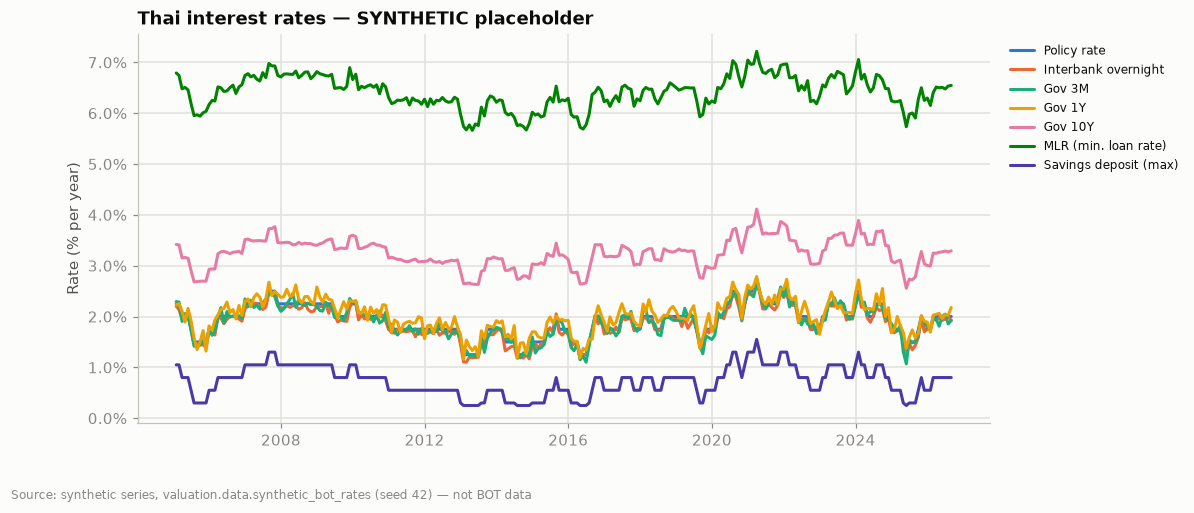

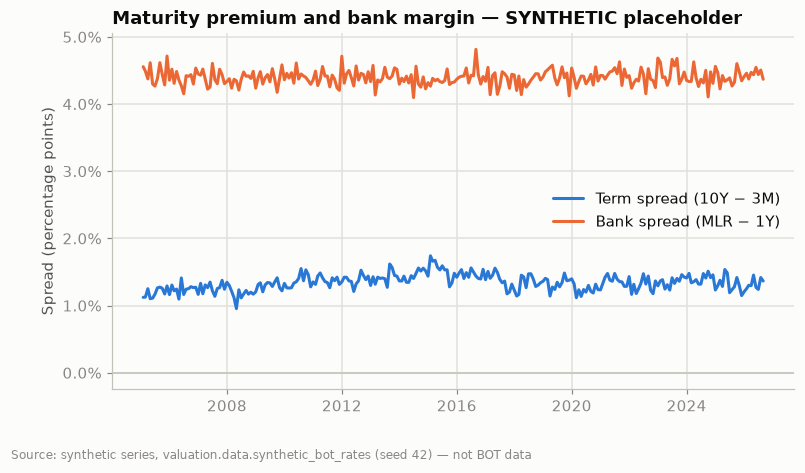

In [4]:
tag = "" if rates_source == "file" else " — SYNTHETIC placeholder"
rate_src = ("Bank of Thailand, data/raw/bot_rates.csv" if rates_source == "file"
            else "synthetic series, valuation.data.synthetic_bot_rates (seed 42) — not BOT data")
labels = {"policy": "Policy rate", "interbank": "Interbank overnight", "gov_3m": "Gov 3M", "gov_1y": "Gov 1Y",
          "gov_10y": "Gov 10Y", "mlr": "MLR (min. loan rate)", "savings": "Savings deposit (max)"}

fig, ax = plt.subplots(figsize=(10, 4.6))
for col, label in labels.items():
    ax.plot(rates.index, rates[col], label=label)
ax.yaxis.set_major_formatter(PCT)
ax.set(title=f"Thai interest rates{tag}", ylabel="Rate (% per year)")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
source_note(fig, rate_src)
plt.show()

term_bank = pd.DataFrame({
    "Term spread (10Y − 3M)": rates["gov_10y"] - rates["gov_3m"],
    "Bank spread (MLR − 1Y)": rates["mlr"] - rates["gov_1y"],
})
fig, ax = plt.subplots()
for col in term_bank:
    ax.plot(term_bank.index, term_bank[col], label=col)
ax.axhline(0, color=AXIS, lw=1)
ax.yaxis.set_major_formatter(PCT)
ax.set(title=f"Maturity premium and bank margin{tag}", ylabel="Spread (percentage points)")
ax.legend()
source_note(fig, rate_src)
plt.show()

What the slide's real chart shows, and what these series are built to mimic:
1. Short rates move together.
2. The 10Y yield sits above them. This is the maturity premium.
3. The MLR sits well above government yields. This is the default and intermediation premium.

To replace the synthetic panel, save BOT monthly data as `data/raw/bot_rates.csv`. It needs a `date` column plus any of `policy, interbank, gov_3m, gov_1y, gov_10y, mlr, savings, cpi_yoy`, in percent.

### 1.2 ThaiBMA corporate spreads (empirical DRP + LP)

In [6]:
pd.concat({"mean spread (bp)": spread_bp, "std dev (bp)": spread_std,
           "avg maturity (y)": spread_tables["maturity"]}, axis=1).style.format("{:.1f}", na_rep="n/a")

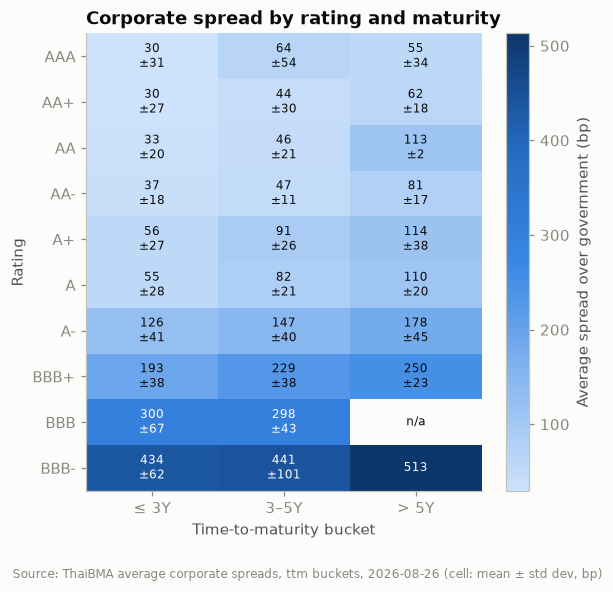

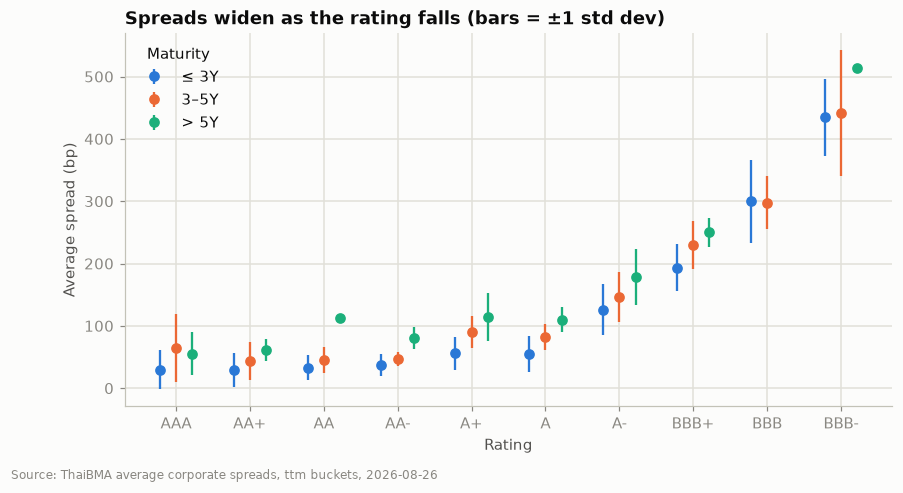

In [7]:
BUCKET_LABELS = ["≤ 3Y", "3–5Y", "> 5Y"]
fig, ax = plt.subplots(figsize=(5.8, 5.4))
im = ax.imshow(spread_bp.to_numpy(), cmap=SEQ, aspect="auto")
ax.set_xticks(range(3), BUCKET_LABELS)
ax.set_yticks(range(len(spread_bp)), spread_bp.index)
ax.grid(False)
for i in range(spread_bp.shape[0]):
    for j in range(spread_bp.shape[1]):
        v, s = spread_bp.iat[i, j], spread_std.iat[i, j]
        label = "n/a" if np.isnan(v) else f"{v:.0f}" + ("" if np.isnan(s) else f"\n±{s:.0f}")
        dark = not np.isnan(v) and im.norm(v) > 0.55
        ax.text(j, i, label, ha="center", va="center", fontsize=8, color="white" if dark else INK)
fig.colorbar(im, ax=ax, label="Average spread over government (bp)")
ax.set(title="Corporate spread by rating and maturity", xlabel="Time-to-maturity bucket", ylabel="Rating")
source_note(fig, "ThaiBMA average corporate spreads, ttm buckets, 2026-08-26 (cell: mean ± std dev, bp)")
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.4))
x = np.arange(len(spread_bp))
for k, (bucket, label) in enumerate(zip(spread_bp.columns, BUCKET_LABELS)):
    ax.errorbar(x + (k - 1) * 0.22, spread_bp[bucket], yerr=spread_std[bucket], fmt="o", ms=6,
                elinewidth=1.5, capsize=0, color=SERIES[k], label=label)
ax.set_xticks(x, spread_bp.index)
ax.set(title="Spreads widen as the rating falls (bars = ±1 std dev)", xlabel="Rating", ylabel="Average spread (bp)")
ax.legend(title="Maturity")
source_note(fig, "ThaiBMA average corporate spreads, ttm buckets, 2026-08-26")
plt.show()

**Reading the table**
- Spreads rise steeply below A, and the BBB− premium is roughly 13× the AAA one.
- Two cells need care:
  - **BBB > 5Y** is empty. `spreads.spread_for` falls back to the nearest bucket and warns.
  - **AAA 3–5Y** (64bp) is above AA+ and AA, but its standard deviation is 54bp, so this looks like a small-sample effect.
- The pricing below uses the **ttm** file because the buckets are by remaining maturity. The duration file is loaded the same way, with `data.load_spread_tables("duration")`.

### 1.3 Rate build-up for a 5-year A-rated bond

In [8]:
T, RATING = 5, "A"
y_short = spreads.gov_yield(GOV_CURVE, 0.25)
real_short = bonds.real_rate(y_short, EXPECTED_INFLATION)          # exact Fisher on the 3M bill
build_up = spreads.rate_build_up(
    real_rf=real_short,
    inflation=y_short - real_short,                                 # so real + inflation = nominal 3M
    drp=spreads.spread_for(RATING, T, spread_bp),                   # ThaiBMA spread = DRP + LP combined
    mp=spreads.gov_yield(GOV_CURVE, T) - y_short,                   # gov curve slope = maturity premium
)
assert abs(build_up["total"] - spreads.corporate_yield(GOV_CURVE, RATING, T, spread_bp)) < 1e-12
(build_up.drop("liquidity premium").rename({"default risk premium": "default + liquidity premium (spread)"})
 .to_frame("rate per year").style.format("{:.3%}"))

,rate per year
real risk-free,0.198%
inflation premium,1.002%
default + liquidity premium (spread),0.822%
maturity premium,0.250%
total,2.272%


---
## 2 · Time value of money — [docs/02](docs/02_time_value_of_money.md)

$$ FV = PV(1+i)^t \;\Longleftrightarrow\; PV = \frac{FV}{(1+i)^t}, \qquad PV = \sum_t \frac{CF_t}{(1+i)^t}, \qquad EAR = \left(1+\tfrac{R_s}{m}\right)^m - 1 $$

### 2.1 100 baht today ≡ 110 in a year ≡ 121 in two years (slides 6–9)

year,value at 10%,PV at year 0
0,100.00,100.00
1,110.00,100.00
2,121.00,100.00


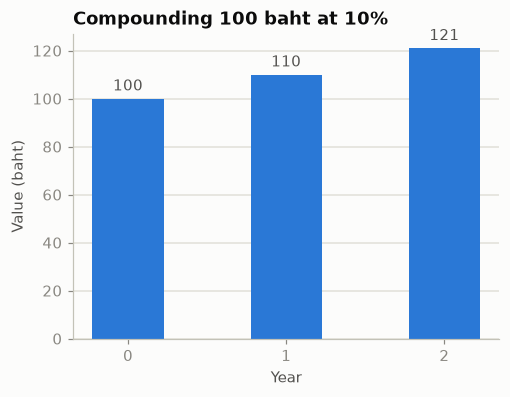

In [9]:
timeline = pd.DataFrame({"year": [0, 1, 2]})
timeline["value at 10%"] = [tvm.fv(100, 0.10, t) for t in timeline["year"]]
timeline["PV at year 0"] = [tvm.pv(v, 0.10, t) for v, t in zip(timeline["value at 10%"], timeline["year"])]
display(timeline.style.format({"value at 10%": "{:.2f}", "PV at year 0": "{:.2f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(5, 3.6))
bars = ax.bar(timeline["year"].astype(str), timeline["value at 10%"], width=0.45, color=SERIES[0])
ax.bar_label(bars, fmt="%.0f", padding=3, color=INK_2)
ax.set(title="Compounding 100 baht at 10%", xlabel="Year", ylabel="Value (baht)")
ax.grid(axis="x", visible=False)
plt.show()

### 2.2 Discounting decays exponentially

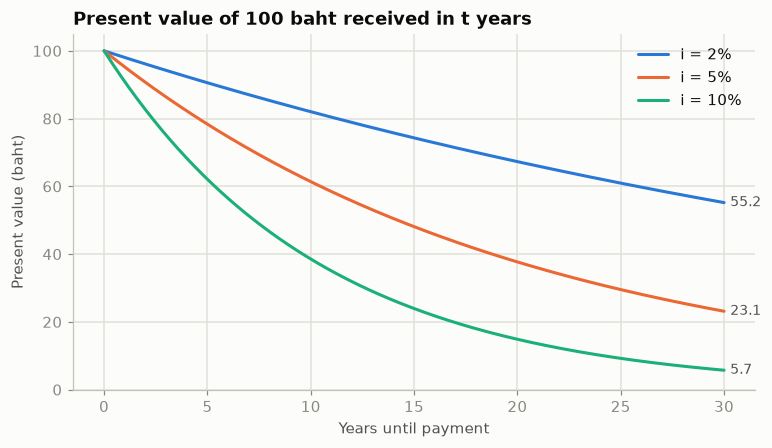

In [10]:
years = np.linspace(0, 30, 301)
fig, ax = plt.subplots()
for k, rate in enumerate([0.02, 0.05, 0.10]):
    pv_curve = 100 * tvm.discount_factor(rate, years)
    ax.plot(years, pv_curve, label=f"i = {rate:.0%}", color=SERIES[k])
    ax.annotate(f"{pv_curve[-1]:.1f}", (years[-1], pv_curve[-1]), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK_2)
ax.set(title="Present value of 100 baht received in t years", xlabel="Years until payment", ylabel="Present value (baht)")
ax.set_ylim(0, 105)
ax.legend()
plt.show()

### 2.3 Compounding frequency and the effective annual rate

,m,EAR at 10% quoted
compounding,,
annual (1),1,10.0000%
semiannual (2),2,10.2500%
quarterly (4),4,10.3813%
monthly (12),12,10.4713%
daily (365),365,10.5156%
continuous (∞),inf,10.5171%


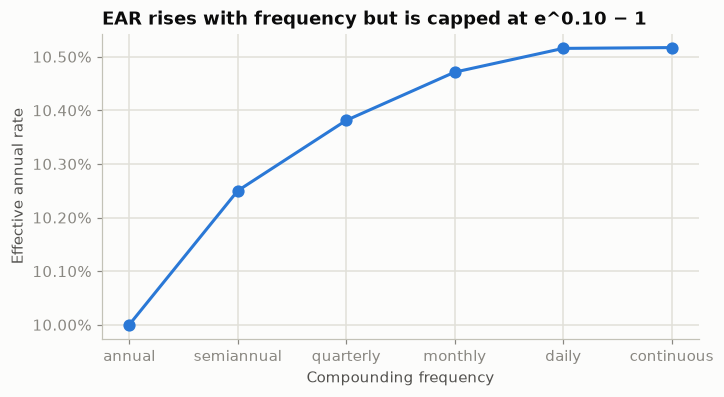

In [11]:
freqs = {"annual (1)": 1, "semiannual (2)": 2, "quarterly (4)": 4, "monthly (12)": 12, "daily (365)": 365, "continuous (∞)": np.inf}
ear_table = pd.DataFrame({"m": list(freqs.values()), "EAR at 10% quoted": [tvm.ear(0.10, m) for m in freqs.values()]},
                         index=pd.Index(freqs.keys(), name="compounding"))
display(ear_table.style.format({"m": "{:g}", "EAR at 10% quoted": "{:.4%}"}))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(range(len(ear_table)), ear_table["EAR at 10% quoted"], marker="o", ms=7, color=SERIES[0])
ax.set_xticks(range(len(ear_table)), [k.split(" ")[0] for k in ear_table.index])
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=2))
ax.set(title="EAR rises with frequency but is capped at e^0.10 − 1", xlabel="Compounding frequency", ylabel="Effective annual rate")
plt.show()

### 2.4 Worked examples (docs/02 test cases)

In [12]:
examples = pd.DataFrame([
    ("FV of 100 at 10% for 2y", tvm.fv(100, 0.10, 2), 121.00),
    ("PV of 250 in 2y at 15% (Mishkin)", tvm.pv(250, 0.15, 2), 189.04),
    ("PV of 100 in 20y at 6.7% (CFA)", tvm.pv(100, 0.067, 20), 27.33),
    ("PV of 100 in 10y at −0.05%", tvm.pv(100, -0.0005, 10), 100.50),
    ("PV of CAD 5m in 10y, 6% monthly", tvm.pv(5_000_000, 0.06, 10, m=12), 2_748_163.67),
    ("Lottery: 1m × 20, first today, 10% (annuity due)", tvm.annuity_pv(1e6, 0.10, 20, due=True), 9_364_920.09),
    ("Loan 100,000, 7%, 20y → payment", tvm.annuity_payment(100_000, 0.07, 20), 9_439.29),
    ("Loan 1,000, payment 85.81, 25y → rate", tvm.annuity_rate(1_000, 85.81, 25), 0.0700),
    ("Perpetuity 100/yr at 10%", tvm.perpetuity_pv(100, 0.10), 1_000.00),
    ("Weekly 0.2% → annual", tvm.annualize(0.002, 52), 0.1095),
    ("18-month 20% → annual", tvm.annualize(0.20, 2 / 3), 0.1292),
    ("Log return 30 → 34.50", tvm.log_return(30, 34.50), 0.139762),
    ("Forward f(1,1) from z1 2%, z2 3%", tvm.forward_rate(0.02, 1, 0.03, 2), 0.040098),
], columns=["case", "computed", "expected"]).set_index("case")
examples["match"] = (examples["computed"] - examples["expected"]).abs() <= np.where(examples["expected"].abs() > 1, 0.01, 1e-4)
assert examples["match"].all()
examples

,computed,expected,match
case,,,
FV of 100 at 10% for 2y,121.0000,121.0000,True
PV of 250 in 2y at 15% (Mishkin),189.0359,189.0400,True
PV of 100 in 20y at 6.7% (CFA),27.3345,27.3300,True
PV of 100 in 10y at −0.05%,100.5014,100.5000,True
"PV of CAD 5m in 10y, 6% monthly","2,748,163.6668","2,748,163.6700",True
"Lottery: 1m × 20, first today, 10% (annuity due)","9,364,920.0917","9,364,920.0900",True
"Loan 100,000, 7%, 20y → payment","9,439.2926","9,439.2900",True
"Loan 1,000, payment 85.81, 25y → rate",0.0700,0.0700,True
Perpetuity 100/yr at 10%,"1,000.0000","1,000.0000",True


### 2.5 Mortgage amortization (CFA: 800,000 at 5.25%/12 for 360 months)

period,payment,interest,principal,balance
1,4417.629617,3500.000000,917.629617,799082.370383
2,4417.629617,3495.985370,921.644247,798160.726136
3,4417.629617,3491.953177,925.676440,797235.049696
359,4417.629617,38.402062,4379.227555,4398.386675
360,4417.629617,19.242942,4398.386675,0.000000


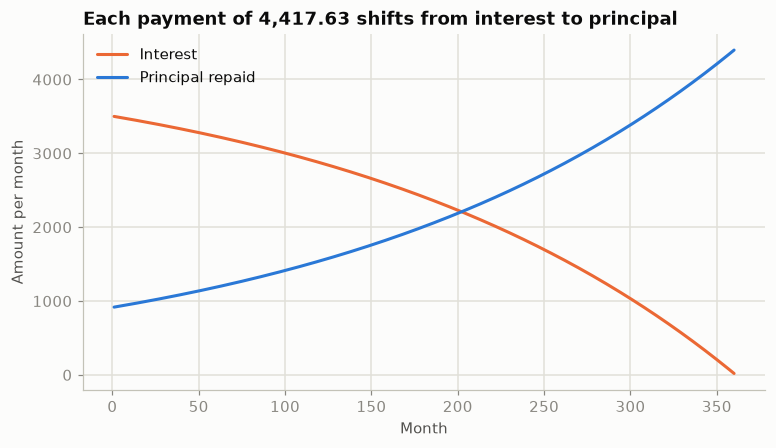

In [13]:
mortgage = tvm.amortization_schedule(800_000, 0.0525 / 12, 360)
assert abs(mortgage.loc[0, "interest"] - 3_500.00) < 0.01
assert abs(mortgage.loc[1, "interest"] - 3_495.99) < 0.01
assert abs(mortgage["balance"].iloc[-1]) < 0.01
display(pd.concat([mortgage.head(3), mortgage.tail(2)]).style.format("{:,.2f}").format({"period": "{:d}"}).hide(axis="index"))

fig, ax = plt.subplots()
ax.plot(mortgage["period"], mortgage["interest"], label="Interest", color=SERIES[1])
ax.plot(mortgage["period"], mortgage["principal"], label="Principal repaid", color=SERIES[0])
ax.set(title=f"Each payment of {mortgage['payment'].iloc[0]:,.2f} shifts from interest to principal",
       xlabel="Month", ylabel="Amount per month")
ax.legend()
plt.show()

---
## 3 · Bonds: yield, return and interest-rate risk — [docs/03](docs/03_debt_valuation.md)

$$ P = \sum_{k=1}^{nm}\frac{C/m}{(1+y/m)^k} + \frac{F}{(1+y/m)^{nm}}, \qquad R = \frac{C + P_{t+1} - P_t}{P_t} = i_c + g $$

### 3.1 The `pv.ipynb` bond, now from `valuation.bonds`

These are the refactored `pv.ipynb` functions, with the same argument names (`par, coupon_rate, months, freq, ytm, tax_rate`). A snapshot test in `tests/test_bonds.py` runs the original function code next to the new module.

> The outputs saved in `pv.ipynb` were computed with the earlier `par = 500,000` (that is why the coupons show as 3,750). With `par = 1,000,000` every amount doubles. The IRR at a 991,000 quote is then **3.32%**, not the −20% shown there.

In [14]:
PV_NB = dict(par=1_000_000, coupon_rate=0.03, months=36, freq=4)
price = bonds.present_value(**PV_NB, ytm=0.05)
price_after_tax = bonds.present_value(**PV_NB, ytm=0.05, tax_rate=TAX_RATE)
print(f"price {price:,.2f} | after-tax price {price_after_tax:,.2f} | PV of coupon tax {price - price_after_tax:,.2f}")
display(bonds.bond_schedule(**PV_NB, ytm=0.05, tax_rate=TAX_RATE).style.format("{:,.2f}")
        .format({"period": "{:d}", "discount_factor": "{:.6f}"}).hide(axis="index"))

quotes = pd.DataFrame({"price": np.arange(850_000, 1_150_001, 50_000).tolist() + [991_000]}).sort_values("price")
quotes["ytm"] = [bonds.bond_ytm(p, **PV_NB) for p in quotes["price"]]
quotes["ytm_after_tax"] = [bonds.bond_ytm(p, **PV_NB, tax_rate=TAX_RATE) for p in quotes["price"]]
quotes.set_index("price").style.format({"ytm": "{:.3%}", "ytm_after_tax": "{:.3%}"}).format_index("{:,.0f}")

price 944,603.44 | after-tax price 932,139.21 | PV of coupon tax 12,464.23


period,time,cash_flow,after_tax_cash_flow,discount_factor,present_value,after_tax_present_value
1,0.250000,7500.000000,6375.000000,0.987654,7407.407407,6296.296296
2,0.500000,7500.000000,6375.000000,0.975461,7315.957933,6218.564243
3,0.750000,7500.000000,6375.000000,0.963418,7225.637465,6141.791845
4,1.000000,7500.000000,6375.000000,0.951524,7136.432064,6065.967255
5,1.250000,7500.000000,6375.000000,0.939777,7048.327965,5991.078770
6,1.500000,7500.000000,6375.000000,0.928175,6961.311570,5917.114834
7,1.750000,7500.000000,6375.000000,0.916716,6875.369452,5844.064034
8,2.000000,7500.000000,6375.000000,0.905398,6790.488347,5771.915095
9,2.250000,7500.000000,6375.000000,0.894221,6706.655158,5700.656884
10,2.500000,7500.000000,6375.000000,0.883181,6623.856946,5630.278404


,ytm,ytm_after_tax
price,,
"850,000",8.738%,8.245%
"900,000",6.708%,6.230%
"950,000",4.799%,4.336%
"991,000",3.316%,2.864%
"1,000,000",3.000%,2.550%
"1,050,000",1.298%,0.860%
"1,100,000",-0.316%,-0.743%
"1,150,000",-1.851%,-2.268%


### 3.2 Mishkin Table 1 (YTM vs price) and Table 2 (one-year returns when rates jump from 10% to 20%)

In [15]:
t1 = bonds.table1()
display(t1.style.format({"price": "{:,.0f}", "ytm": "{:.2%}"}).hide(axis="index"))

t2 = bonds.table2()
assert t2["next_price"].round().tolist() == [503, 516, 597, 741, 917, 1000]
assert (t2["return"] * 100).round(1).tolist() == [-39.7, -38.4, -30.3, -15.9, 1.7, 10.0]
t2.style.format({"initial_price": "{:,.0f}", "next_price": "{:,.0f}", "current_yield": "{:.1%}",
                 "capital_gain": "{:+.1%}", "return": "{:+.1%}"})

price,ytm
"1,200",7.13%
"1,100",8.48%
"1,000",10.00%
900,11.75%
800,13.81%


,initial_price,next_price,current_yield,capital_gain,return
years_to_maturity,,,,,
30,"1,000",503,10.0%,-49.7%,-39.7%
20,"1,000",516,10.0%,-48.4%,-38.4%
10,"1,000",597,10.0%,-40.3%,-30.3%
5,"1,000",741,10.0%,-25.9%,-15.9%
2,"1,000",917,10.0%,-8.3%,+1.7%
1,"1,000","1,000",10.0%,+0.0%,+10.0%


Table 2 makes four points:
- Only the bond whose maturity equals the holding period earns its YTM.
- The longer the maturity, the larger the capital loss when rates rise.
- A bond with a 10% YTM can return −40% in one year.
- **Interest-rate risk grows with maturity.**

### 3.3 Three facts about price and yield, and current yield as an approximation

price at par ⇔ YTM = coupon     True
price falls as YTM rises        True
discount bond ⇒ YTM > coupon    True
premium bond ⇒ YTM < coupon     True
Name: holds, dtype: bool

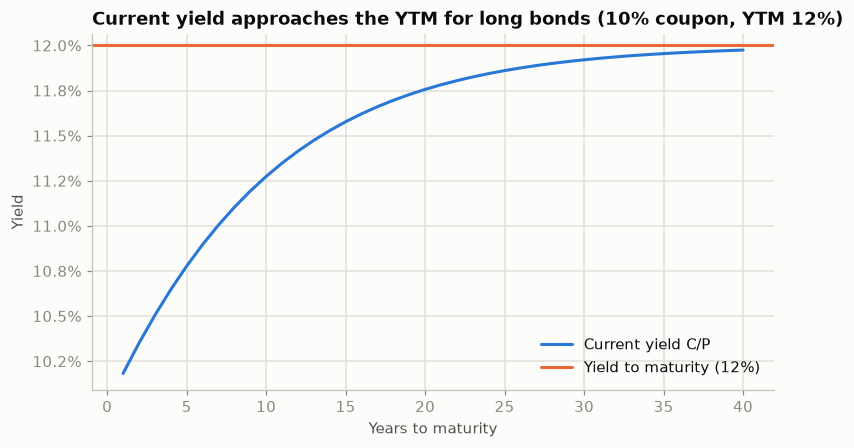

20-year bond: price 850.61, current yield 11.76% vs YTM 12.00%


In [16]:
facts = {
    "price at par ⇔ YTM = coupon": abs(bonds.bond_ytm(1000, 1000, 0.10, 120) - 0.10) < 1e-10,
    "price falls as YTM rises": bool(np.all(np.diff(bonds.bond_price(1000, 0.10, 120, np.linspace(0.02, 0.2, 50))) < 0)),
    "discount bond ⇒ YTM > coupon": bonds.bond_ytm(900, 1000, 0.10, 120) > 0.10,
    "premium bond ⇒ YTM < coupon": bonds.bond_ytm(1100, 1000, 0.10, 120) < 0.10,
}
assert all(facts.values())
display(pd.Series(facts, name="holds"))

maturities = np.arange(1, 41)
cy = [bonds.current_yield(100, bonds.bond_price(1000, 0.10, 12 * n, 0.12)) for n in maturities]
fig, ax = plt.subplots()
ax.plot(maturities, cy, color=SERIES[0], label="Current yield C/P")
ax.axhline(0.12, color=SERIES[1], lw=2, label="Yield to maturity (12%)")
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
ax.set(title="Current yield approaches the YTM for long bonds (10% coupon, YTM 12%)",
       xlabel="Years to maturity", ylabel="Yield")
ax.legend(loc="lower right")
plt.show()
print(f"20-year bond: price {bonds.bond_price(1000, 0.10, 240, 0.12):.2f}, current yield {cy[19]:.2%} vs YTM 12.00%")

### 3.4 Return vs YTM under parallel rate shocks (one-year holding period, 10% coupon bonds bought at par)

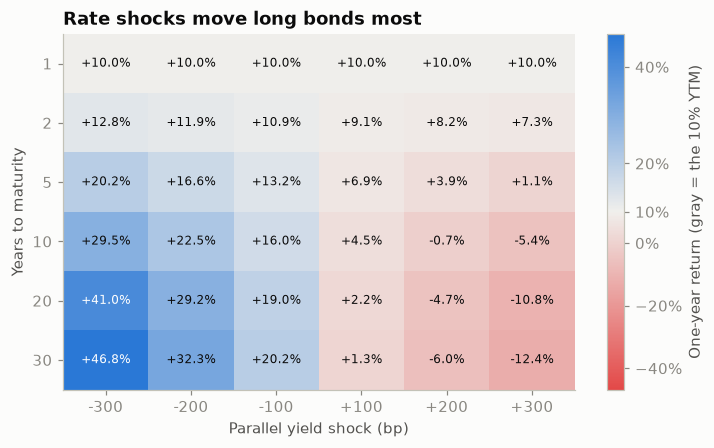

In [17]:
shock = bonds.shock_returns([-300, -200, -100, 100, 200, 300], [1, 2, 5, 10, 20, 30])
fig, ax = plt.subplots(figsize=(7.5, 4.2))
lim = np.abs(shock.to_numpy()).max()
im = ax.imshow(shock.to_numpy(), cmap=DIV, norm=TwoSlopeNorm(0.10, -lim, max(lim, 0.11)), aspect="auto")
ax.set_xticks(range(shock.shape[1]), [f"{s:+d}" for s in shock.columns])
ax.set_yticks(range(shock.shape[0]), shock.index)
ax.grid(False)
for i in range(shock.shape[0]):
    for j in range(shock.shape[1]):
        c = im.norm(shock.iat[i, j])
        ax.text(j, i, f"{shock.iat[i, j]:+.1%}", ha="center", va="center", fontsize=8,
                color="white" if c < 0.15 or c > 0.85 else INK)
fig.colorbar(im, ax=ax, label="One-year return (gray = the 10% YTM)", format=PCT, ticks=[-0.4, -0.2, 0, 0.1, 0.2, 0.4])
ax.set(title="Rate shocks move long bonds most", xlabel="Parallel yield shock (bp)", ylabel="Years to maturity")
plt.show()

### 3.5 Reinvestment risk (Mishkin fn. 6): a 2-year horizon rolling 1-year bonds

In [17]:
roll = pd.DataFrame({"path": ["10% then 20%", "10% then 5%"], "rates": [[0.10, 0.20], [0.10, 0.05]]})
roll["value of 1,000"] = [bonds.rollover_value(1000, r) for r in roll["rates"]]
roll["annualized"] = [tvm.annualize(v / 1000 - 1, 1 / 2) for v in roll["value of 1,000"]]
roll.set_index("path").style.format({"value of 1,000": "{:,.0f}", "annualized": "{:.2%}"})

,rates,"value of 1,000",annualized
path,,,
10% then 20%,"[0.1, 0.2]","1,320",14.89%
10% then 5%,"[0.1, 0.05]","1,155",7.47%


When rates rise, the rolling investor *gains*. This is the opposite of the long-bond holder in Table 2. Mishkin prints 7.2% for the low path, but recomputing gives $\sqrt{1.155}-1 = 7.47\%$.

### 3.6 Duration and convexity

,"10% annual coupon, 10y, y = 10%"
price,"1,000.0000"
macaulay,6.7590
modified,6.1446
convexity,52.7926
dv01,0.6145
finite-difference duration,6.1446
finite-difference convexity,52.7926


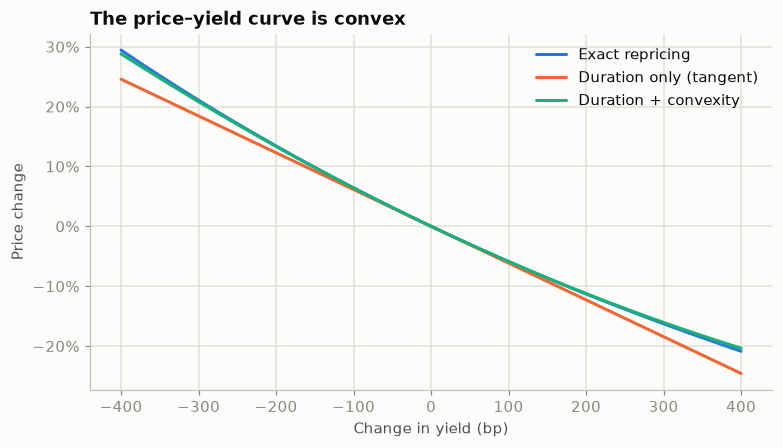

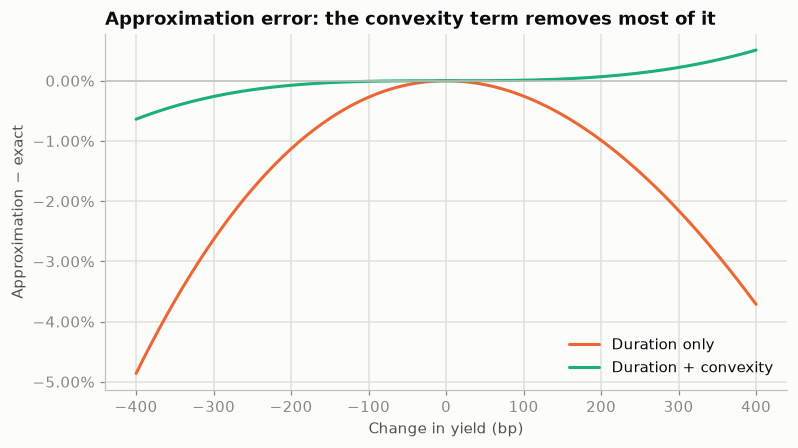

+100bp: approximation -5.881%, exact -5.889%


In [18]:
BOND_10Y = dict(par=1000, coupon_rate=0.10, months=120)
risk = bonds.duration(**BOND_10Y, ytm=0.10)
fd = bonds.effective_duration(**BOND_10Y, ytm=0.10)
display(pd.Series({**risk, "finite-difference duration": fd["duration"], "finite-difference convexity": fd["convexity"]},
                  name="10% annual coupon, 10y, y = 10%").to_frame())

dy = np.linspace(-0.04, 0.04, 161)
exact = bonds.bond_price(**BOND_10Y, ytm=0.10 + dy) / risk["price"] - 1
first = bonds.price_change_approx(risk["modified"], 0.0, dy)
second = bonds.price_change_approx(risk["modified"], risk["convexity"], dy)

fig, ax = plt.subplots()
ax.plot(dy * 10_000, exact, label="Exact repricing", color=SERIES[0])
ax.plot(dy * 10_000, first, label="Duration only (tangent)", color=SERIES[1])
ax.plot(dy * 10_000, second, label="Duration + convexity", color=SERIES[2])
ax.yaxis.set_major_formatter(PCT)
ax.set(title="The price–yield curve is convex", xlabel="Change in yield (bp)", ylabel="Price change")
ax.legend()
plt.show()

fig, ax = plt.subplots()
ax.plot(dy * 10_000, first - exact, label="Duration only", color=SERIES[1])
ax.plot(dy * 10_000, second - exact, label="Duration + convexity", color=SERIES[2])
ax.axhline(0, color=AXIS, lw=1)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=2))
ax.set(title="Approximation error: the convexity term removes most of it", xlabel="Change in yield (bp)",
       ylabel="Approximation − exact")
ax.legend()
plt.show()
print(f"+100bp: approximation {bonds.price_change_approx(risk['modified'], risk['convexity'], 0.01):.3%}, "
      f"exact {bonds.bond_price(**BOND_10Y, ytm=0.11) / 1000 - 1:.3%}")

### 3.7 Real vs nominal rates (Fisher)

,real rate,expected
case,,
"i 5%, π 3% (approx.)",2.00%,2.00%
"i 8%, π 10% (approx.)",-2.00%,-2.00%
"after-tax: i 10%, τ 30%, π 5%",2.00%,2.00%
"exact: 2.4% after-tax nominal, π 2% (CFA)",0.39%,0.39%


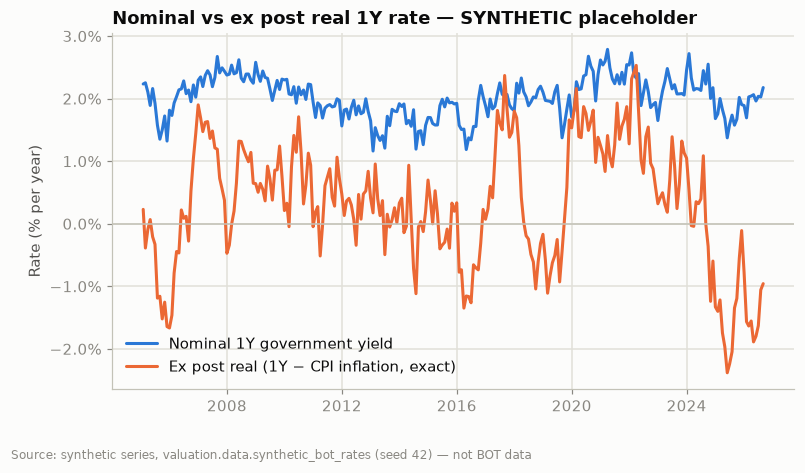

In [19]:
fisher = pd.DataFrame([
    ("i 5%, π 3% (approx.)", bonds.real_rate(0.05, 0.03, exact=False), 0.02),
    ("i 8%, π 10% (approx.)", bonds.real_rate(0.08, 0.10, exact=False), -0.02),
    ("after-tax: i 10%, τ 30%, π 5%", bonds.after_tax_real(0.10, 0.30, 0.05), 0.02),
    ("exact: 2.4% after-tax nominal, π 2% (CFA)", bonds.real_rate(0.024, 0.02, exact=True), 0.0039),
], columns=["case", "real rate", "expected"]).set_index("case")
assert ((fisher["real rate"] - fisher["expected"]).abs() < 1e-4).all()
display(fisher.style.format("{:.2%}"))

ex_post = bonds.real_rate(rates["gov_1y"], rates["cpi_yoy"])
fig, ax = plt.subplots()
ax.plot(rates.index, rates["gov_1y"], label="Nominal 1Y government yield", color=SERIES[0])
ax.plot(rates.index, ex_post, label="Ex post real (1Y − CPI inflation, exact)", color=SERIES[1])
ax.axhline(0, color=AXIS, lw=1)
ax.yaxis.set_major_formatter(PCT)
ax.set(title=f"Nominal vs ex post real 1Y rate{tag}", ylabel="Rate (% per year)")
ax.legend()
source_note(fig, rate_src)
plt.show()

### 3.8 Corporate bond pricing by rating (docs/03 §3.10)

Here a single bond (5 years, 3% coupon, semiannual, par 100) is discounted at $y_{gov}(5) + \text{spread}(\text{rating}, 5)$. The government yield comes from the placeholder `GOV_CURVE` and the spread from the ThaiBMA table.

,gov_yield,spread_bp,yield,price,note
rating,,,,,
AAA,1.45%,64,2.09%,104.31,
AA+,1.45%,44,1.89%,105.27,
AA,1.45%,46,1.91%,105.18,
AA-,1.45%,47,1.92%,105.12,
A+,1.45%,91,2.36%,103.01,
A,1.45%,82,2.27%,103.42,
A-,1.45%,147,2.92%,100.39,
BBB+,1.45%,229,3.74%,96.64,
BBB,1.45%,298,4.43%,93.65,


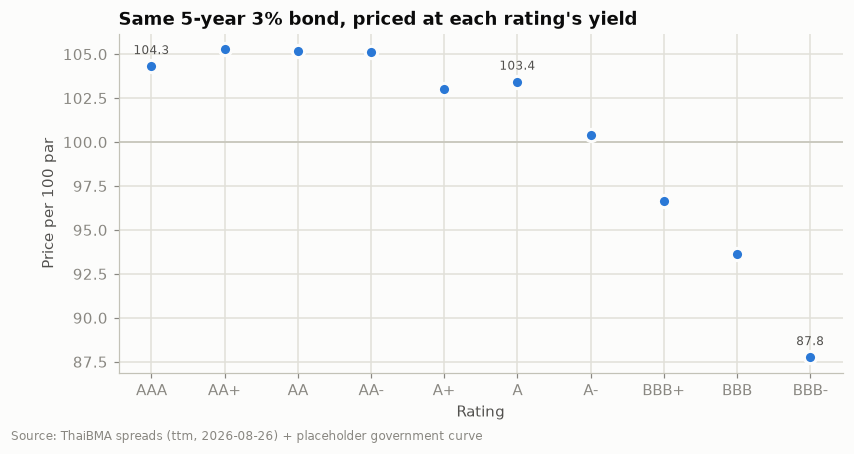

In [20]:
by_rating = spreads.price_by_rating(100, 0.03, 60, GOV_CURVE, spread_bp, freq=2)
display(by_rating.style.format({"gov_yield": "{:.2%}", "spread_bp": "{:.0f}", "yield": "{:.2%}", "price": "{:.2f}"}))

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.axhline(100, color=AXIS, lw=1)
ax.annotate("par", (len(by_rating) - 0.5, 100), xytext=(0, 3), textcoords="offset points", ha="right", fontsize=8, color=INK_2)
ax.plot(by_rating.index, by_rating["price"], marker="o", ms=8, lw=0, color=SERIES[0], markeredgecolor=SURFACE, markeredgewidth=2)
for rating in [by_rating.index[0], "A", by_rating.index[-1]]:
    ax.annotate(f"{by_rating.loc[rating, 'price']:.1f}", (rating, by_rating.loc[rating, "price"]), xytext=(0, 8),
                textcoords="offset points", ha="center", fontsize=8, color=INK_2)
ax.set(title="Same 5-year 3% bond, priced at each rating's yield", xlabel="Rating", ylabel="Price per 100 par")
source_note(fig, "ThaiBMA spreads (ttm, 2026-08-26) + placeholder government curve")
plt.show()

---
## 4 · Common stock valuation — [docs/04](docs/04_equity_valuation.md)

$$ P_0 = \frac{D_1 + P_1}{1+k_e} \;\to\; P_0 = \sum_{t=1}^{\infty}\frac{D_t}{(1+k_e)^t} \;\to\; P_0 = \frac{D_1}{k_e-g}\;(k_e>g) $$

### 4.1 Worked examples

In [21]:
eq_examples = pd.DataFrame([
    ("One-period, Intel: D1 0.16, P1 60, ke 12%", equity.one_period_price(0.16, 60, 0.12), 53.71),
    ("PV of 50 received in 75y at 12%", equity.ddm_explicit([0] * 75, 0.12, terminal_price=50), 0.0102),
    ("Gordon: D1 2, g 3%, ke 15%", equity.gordon_price(0.15, 0.03, d1=2), 16.67),
    ("Gordon: D1 2, g 3%, ke 12%", equity.gordon_price(0.12, 0.03, d1=2), 22.22),
    ("Gordon: D1 2, g 3%, ke 10%", equity.gordon_price(0.10, 0.03, d1=2), 28.57),
    ("Shipline: D0 1.50, g 6%, ke 15%", equity.gordon_price(0.15, 0.06, d0=1.50), 17.67),
    ("Shipline: constant 1.50, ke 15%", equity.gordon_price(0.15, 0.0, d1=1.50), 10.00),
    ("Coke: implied ke (P 63, D1 1.76, g 4%)", equity.gordon_implied_return(63, 1.76, 0.04), 0.0679),
    ("Coke: implied g (P 63, D1 1.76, ke 7%)", equity.gordon_implied_growth(63, 1.76, 0.07), 0.0421),
    ("Justified forward P/E (payout 70%, ke 9%, g 4.5%)", equity.justified_forward_pe(0.70, 0.09, 0.045), 15.56),
], columns=["case", "computed", "expected"]).set_index("case")
assert ((eq_examples["computed"] - eq_examples["expected"]).abs() <= 0.01).all()
display(eq_examples)

two_stage = pd.DataFrame({"g_long": [0.0, 0.02, 0.04, 0.06]})
two_stage["price"] = [equity.two_stage_ddm(1.5, 0.06, 3, g, 0.15) for g in two_stage["g_long"]]
assert two_stage["price"].round(2).tolist() == [11.66, 13.05, 14.94, 17.67]
detail = equity.two_stage_ddm(1.5, 0.06, 3, 0.02, 0.15, detail=True)
print(f"Two-stage Shipline (gS 6% for 3y, ke 15%); gL = 2%: PV stage 1 {detail['pv_stage1']:.3f} "
      f"+ PV terminal {detail['pv_terminal']:.2f} = {detail['price']:.2f}")
two_stage.style.format({"g_long": "{:.0%}", "price": "{:.2f}"}).hide(axis="index")

,computed,expected
case,,
"One-period, Intel: D1 0.16, P1 60, ke 12%",53.7143,53.7100
PV of 50 received in 75y at 12%,0.0102,0.0102
"Gordon: D1 2, g 3%, ke 15%",16.6667,16.6700
"Gordon: D1 2, g 3%, ke 12%",22.2222,22.2200
"Gordon: D1 2, g 3%, ke 10%",28.5714,28.5700
"Shipline: D0 1.50, g 6%, ke 15%",17.6667,17.6700
"Shipline: constant 1.50, ke 15%",10.0000,10.0000
"Coke: implied ke (P 63, D1 1.76, g 4%)",0.0679,0.0679
"Coke: implied g (P 63, D1 1.76, ke 7%)",0.0421,0.0421


Two-stage Shipline (gS 6% for 3y, ke 15%); gL = 2%: PV stage 1 3.832 + PV terminal 9.22 = 13.05


g_long,price
0%,11.66
2%,13.05
4%,14.94
6%,17.67


### 4.2 The explicit DDM converges to Gordon as the horizon grows (D0 1.50, g 6%, ke 15%)

,explicit DDM,share of Gordon
n,,
10,9.8462,0.5573
25,15.3633,0.8696
50,17.3664,0.9830
100,17.6616,0.9997
200,17.6667,1.0000
500,17.6667,1.0000


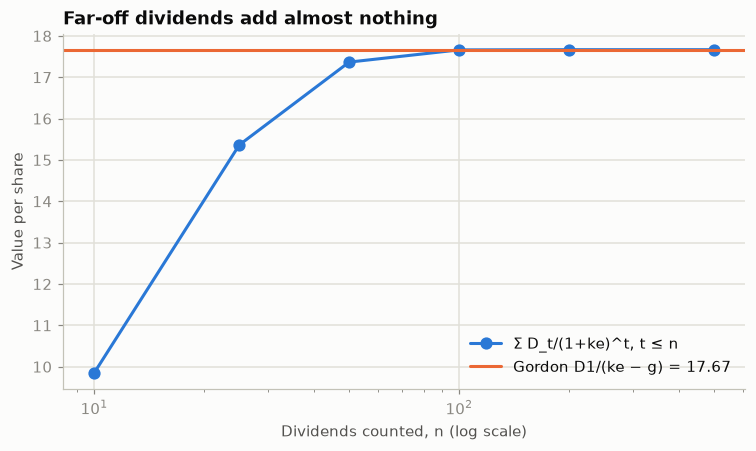

In [22]:
gordon_value = equity.gordon_price(0.15, 0.06, d0=1.50)
horizons = [10, 25, 50, 100, 200, 500]
convergence = pd.DataFrame({"n": horizons,
                            "explicit DDM": [equity.ddm_explicit(equity.growing_dividends(1.50, 0.06, n), 0.15) for n in horizons]})
convergence["share of Gordon"] = convergence["explicit DDM"] / gordon_value
display(convergence.set_index("n"))

fig, ax = plt.subplots()
ax.plot(convergence["n"], convergence["explicit DDM"], marker="o", ms=7, color=SERIES[0], label="Σ D_t/(1+ke)^t, t ≤ n")
ax.axhline(gordon_value, color=SERIES[1], lw=2, label=f"Gordon D1/(ke − g) = {gordon_value:.2f}")
ax.set_xscale("log")
ax.set(title="Far-off dividends add almost nothing", xlabel="Dividends counted, n (log scale)", ylabel="Value per share")
ax.legend(loc="lower right")
plt.show()

### 4.3 Sensitivity of the Gordon price to $k_e$ and $g$ (D1 = 2; cells with $g \ge k_e$ masked)

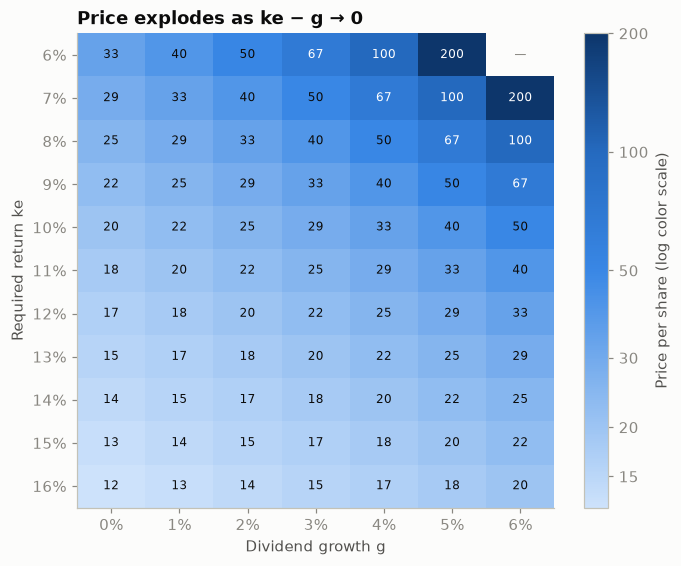

At ke 12%, g 3%: ∂P/∂g = 246.9 and ∂P/∂ke = -246.9 per unit, so +1pp of g adds about 2.47 to a price of 22.22.


In [23]:
ke_grid = np.round(np.arange(0.06, 0.1601, 0.01), 4)
g_grid = np.round(np.arange(0.0, 0.0601, 0.01), 4)
grid = pd.DataFrame([[equity.gordon_price(k, g, d1=2) if k > g else np.nan for g in g_grid] for k in ke_grid],
                    index=ke_grid, columns=g_grid)

fig, ax = plt.subplots(figsize=(7, 5.6))
im = ax.imshow(grid.to_numpy(), cmap=SEQ, norm=LogNorm(np.nanmin(grid.to_numpy()), np.nanmax(grid.to_numpy())), aspect="auto")
ax.set_xticks(range(len(g_grid)), [f"{g:.0%}" for g in g_grid])
ax.set_yticks(range(len(ke_grid)), [f"{k:.0%}" for k in ke_grid])
ax.grid(False)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.iat[i, j]
        ax.text(j, i, "—" if np.isnan(v) else f"{v:.0f}", ha="center", va="center", fontsize=8,
                color=MUTED if np.isnan(v) else ("white" if im.norm(v) > 0.55 else INK))
cb = fig.colorbar(im, ax=ax, label="Price per share (log color scale)", ticks=[15, 20, 30, 50, 100, 200])
cb.ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}"))
cb.ax.minorticks_off()
ax.set(title="Price explodes as ke − g → 0", xlabel="Dividend growth g", ylabel="Required return ke")
plt.show()
s = equity.gordon_sensitivity(0.12, 0.03, 2)
print(f"At ke 12%, g 3%: ∂P/∂g = {s['dP_dg']:.1f} and ∂P/∂ke = {s['dP_dke']:.1f} per unit, "
      f"so +1pp of g adds about {s['dP_dg'] * 0.01:.2f} to a price of {equity.gordon_price(0.12, 0.03, d1=2):.2f}.")

### 4.4 Who sets the price? (slides 16–17, Mishkin auction example)

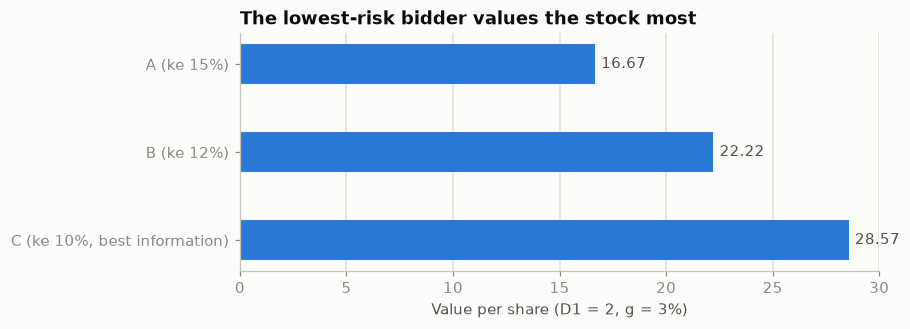

In [24]:
bidders = pd.DataFrame({"investor": ["A (ke 15%)", "B (ke 12%)", "C (ke 10%, best information)"],
                        "ke": [0.15, 0.12, 0.10]})
bidders["value"] = [equity.gordon_price(k, 0.03, d1=2) for k in bidders["ke"]]
fig, ax = plt.subplots(figsize=(7.5, 2.8))
bars = ax.barh(bidders["investor"], bidders["value"], height=0.45, color=SERIES[0])
ax.bar_label(bars, fmt="%.2f", padding=4, color=INK_2)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set(title="The lowest-risk bidder values the stock most", xlabel="Value per share (D1 = 2, g = 3%)")
plt.show()

C outbids the others, so the market price lands between 22.22 (B's value) and 28.57 (C's). Better information lowers the perceived risk, which lowers $k_e$ and raises the price. The Thai case ("what $g$ is right for PTT?") needs a CAPM $k_e$, so it is in §7, after §5 has estimated beta.

---
## 5 · Returns, risk and CAPM — [docs/05](docs/05_risk_return_capm.md)

$$ R_i - r_f = \alpha_i + \beta_i(R_m - r_f) + \varepsilon_i, \qquad \sigma_i^2 = \beta_i^2\sigma_m^2 + \sigma_\varepsilon^2, \qquad k_e = r_f + \beta\,(r_m - r_f) $$

**Conventions**
- **Returns:** monthly, from yfinance *adjusted* close. Adjusted close includes dividends, so it is an approximate total return.
- **Market:** `TDEX.BK`, a SET50 ETF. The SET TRI is not available on yfinance.
- **Risk-free rate:** in the regressions, $r_f$ is the 3M government yield ÷ 12, taken from the placeholder curve.
- **Beta window:** the last 60 months.
- **Annualizing:** for the SML, means are annualized ×12, so a stock's distance from the line equals 12 × its regression alpha.

### 5.1 Return statistics (full sample)

In [25]:
monthly = returns.period_returns(market.adj_close, "ME")
stats = returns.summary_stats(monthly, periods_per_year=12)
print(f"Monthly returns {monthly.index.min():%Y-%m} → {monthly.index.max():%Y-%m}")
stats.style.format({"n": "{:.0f}", "mean": "{:.2%}", "geo_mean": "{:.2%}", "std": "{:.2%}",
                    "ann_mean": "{:.1%}", "ann_geo_mean": "{:.1%}", "ann_vol": "{:.1%}"})

Monthly returns 2015-02 → 2026-09


,n,mean,geo_mean,std,ann_mean,ann_geo_mean,ann_vol
PTT.BK,140,0.72%,0.51%,6.54%,9.0%,6.3%,22.7%
PTTEP.BK,140,0.98%,0.62%,8.41%,12.4%,7.7%,29.1%
ADVANC.BK,140,0.81%,0.64%,5.72%,10.1%,8.0%,19.8%
AOT.BK,140,0.81%,0.53%,7.70%,10.2%,6.5%,26.7%
CPALL.BK,140,0.37%,0.17%,6.37%,4.5%,2.1%,22.1%
KBANK.BK,140,0.62%,0.35%,7.49%,7.6%,4.3%,25.9%
BBL.BK,140,0.47%,0.32%,5.53%,5.8%,3.9%,19.2%
SCC.BK,140,-0.00%,-0.20%,6.30%,-0.0%,-2.3%,21.8%
BDMS.BK,140,0.39%,0.22%,5.85%,4.8%,2.7%,20.3%
TDEX.BK,140,0.45%,0.34%,4.58%,5.5%,4.2%,15.9%


### 5.2 Diversification: portfolio risk vs number of stocks

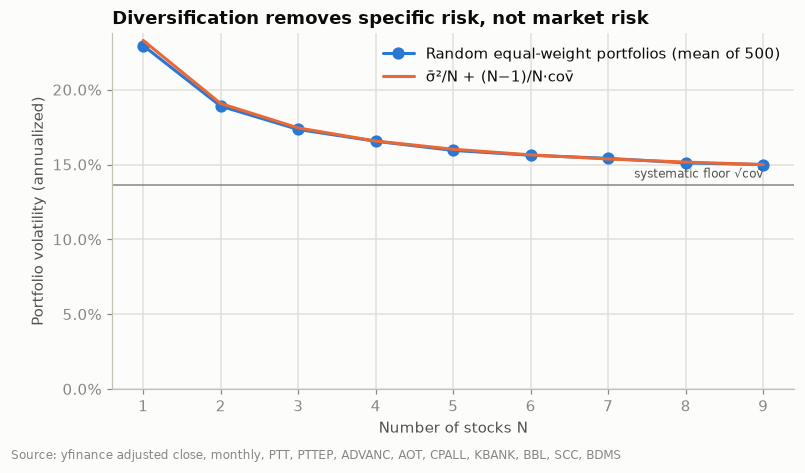

In [26]:
div_curve = returns.diversification_curve(monthly[STOCKS], n_sims=500, seed=42)
ann = np.sqrt(12)
fig, ax = plt.subplots()
ax.plot(div_curve.index, div_curve["simulated_std"] * ann, marker="o", ms=7, color=SERIES[0],
        label="Random equal-weight portfolios (mean of 500)")
ax.plot(div_curve.index, div_curve["formula_std"] * ann, color=SERIES[1], label="σ̄²/N + (N−1)/N·cov̄")
ax.axhline(div_curve.attrs["floor_std"] * ann, color=MUTED, lw=1)
ax.annotate("systematic floor √cov̄", (div_curve.index[-1], div_curve.attrs["floor_std"] * ann), xytext=(0, 5),
            textcoords="offset points", ha="right", fontsize=8, color=INK_2)
ax.yaxis.set_major_formatter(PCT)
ax.set_ylim(0, None)
ax.set(title="Diversification removes specific risk, not market risk", xlabel="Number of stocks N",
       ylabel="Portfolio volatility (annualized)")
ax.legend()
source_note(fig, f"yfinance adjusted close, monthly, {', '.join(s.removesuffix('.BK') for s in STOCKS)}")
plt.show()

### 5.3 Beta, alpha (per month) and R² (last 60 months, excess returns)

In [27]:
window = monthly.iloc[-BETA_MONTHS:]
rf_month = RF_3M / 12
betas = pd.DataFrame({t: capm.estimate_beta(window[t], window[MARKET], rf=rf_month) for t in STOCKS}).T
betas["blume_beta"] = capm.blume_beta(betas["beta"])
print(f"Window {window.index.min():%Y-%m} → {window.index.max():%Y-%m}, n = {len(window)}")
betas[["alpha", "t_alpha", "beta", "se_beta", "t_beta", "blume_beta", "r2", "resid_std"]].style.format(
    {"alpha": "{:+.2%}", "t_alpha": "{:+.2f}", "beta": "{:.2f}", "se_beta": "{:.2f}", "t_beta": "{:.1f}",
     "blume_beta": "{:.2f}", "r2": "{:.2f}", "resid_std": "{:.2%}"})

Window 2021-10 → 2026-09, n = 60


,alpha,t_alpha,beta,se_beta,t_beta,blume_beta,r2,resid_std
PTT.BK,+0.25%,+0.46,0.55,0.13,4.3,0.70,0.24,4.19%
PTTEP.BK,+0.78%,+0.86,0.44,0.21,2.1,0.62,0.07,6.98%
ADVANC.BK,+1.06%,+1.84,0.62,0.13,4.7,0.75,0.27,4.42%
AOT.BK,-0.39%,-0.45,1.23,0.20,6.2,1.15,0.40,6.59%
CPALL.BK,-0.91%,-1.47,0.96,0.14,6.7,0.98,0.44,4.76%
KBANK.BK,+1.11%,+1.91,0.56,0.14,4.2,0.71,0.23,4.48%
BBL.BK,+0.87%,+1.61,0.58,0.13,4.6,0.72,0.27,4.14%
SCC.BK,-0.83%,-0.99,0.88,0.20,4.5,0.92,0.26,6.47%
BDMS.BK,-0.28%,-0.49,0.54,0.13,4.1,0.69,0.22,4.39%


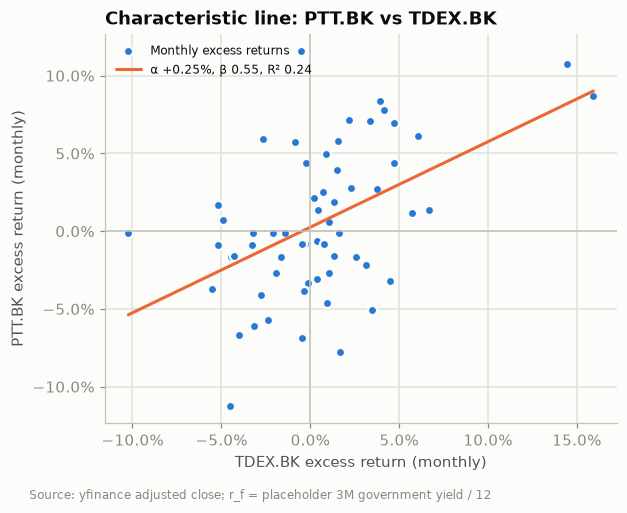

In [28]:
y_ex, x_ex = window[STOCK] - rf_month, window[MARKET] - rf_month
fit = betas.loc[STOCK]
xs = np.linspace(x_ex.min(), x_ex.max(), 2)
fig, ax = plt.subplots(figsize=(6, 4.6))
ax.scatter(x_ex, y_ex, s=36, color=SERIES[0], edgecolor=SURFACE, linewidth=1.5, label="Monthly excess returns")
ax.plot(xs, fit["alpha"] + fit["beta"] * xs, color=SERIES[1], label=f"α {fit['alpha']:+.2%}, β {fit['beta']:.2f}, R² {fit['r2']:.2f}")
ax.axhline(0, color=AXIS, lw=1); ax.axvline(0, color=AXIS, lw=1)
ax.xaxis.set_major_formatter(PCT); ax.yaxis.set_major_formatter(PCT)
ax.set(title=f"Characteristic line: {STOCK} vs {MARKET}", xlabel=f"{MARKET} excess return (monthly)",
       ylabel=f"{STOCK} excess return (monthly)")
ax.legend(loc="upper left", fontsize=8)
source_note(fig, "yfinance adjusted close; r_f = placeholder 3M government yield / 12")
plt.show()

### 5.4 Security Market Line (same 60-month window)

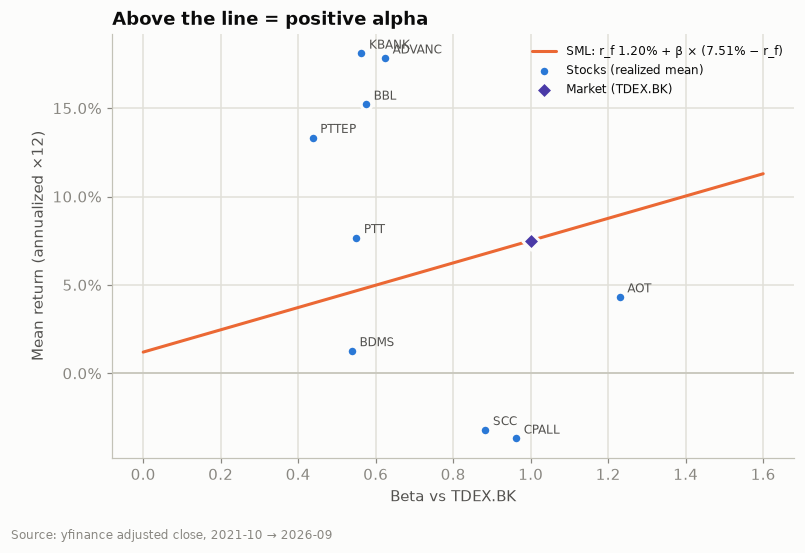

In [29]:
rm_window = window[MARKET].mean() * 12
realized = window[STOCKS].mean() * 12
sml_alpha = capm.sml_alpha(realized, RF_3M, betas["beta"], rm_window)
assert np.allclose(sml_alpha, betas["alpha"] * 12)   # distance from the SML = 12 × regression alpha

bs = np.linspace(0, max(1.6, betas["beta"].max() + 0.1), 50)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(bs, capm.capm_required_return(RF_3M, bs, rm=rm_window), color=SERIES[1],
        label=f"SML: r_f {RF_3M:.2%} + β × ({rm_window:.2%} − r_f)")
ax.scatter(betas["beta"], realized, s=48, color=SERIES[0], edgecolor=SURFACE, linewidth=2, zorder=3, label="Stocks (realized mean)")
ax.scatter([1.0], [rm_window], s=64, marker="D", color=SERIES[6], edgecolor=SURFACE, linewidth=2, zorder=3, label=f"Market ({MARKET})")
for t in STOCKS:
    ax.annotate(t.removesuffix(".BK"), (betas.loc[t, "beta"], realized[t]), xytext=(5, 3), textcoords="offset points",
                fontsize=8, color=INK_2)
ax.axhline(0, color=AXIS, lw=1)
ax.yaxis.set_major_formatter(PCT)
ax.set(title="Above the line = positive alpha", xlabel="Beta vs " + MARKET, ylabel="Mean return (annualized ×12)")
ax.legend(fontsize=8, loc="upper right")
source_note(fig, f"yfinance adjusted close, {window.index.min():%Y-%m} → {window.index.max():%Y-%m}")
plt.show()

### 5.5 Systematic vs specific risk

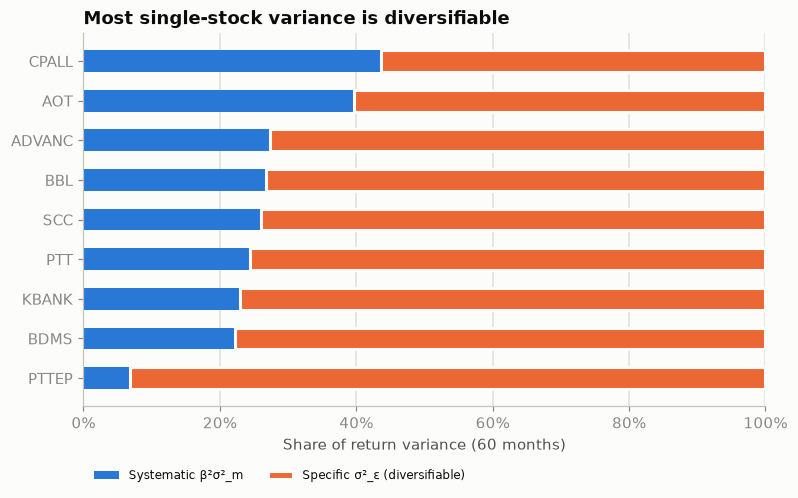

In [30]:
decomp = pd.DataFrame({t: capm.variance_decomposition(window[t], window[MARKET], rf=rf_month) for t in STOCKS}).T
decomp = decomp.sort_values("systematic_share")
fig, ax = plt.subplots(figsize=(8, 4.4))
labels = [t.removesuffix(".BK") for t in decomp.index]
ax.barh(labels, decomp["systematic_share"], height=0.55, color=SERIES[0], label="Systematic β²σ²_m")
ax.barh(labels, 1 - decomp["systematic_share"], left=decomp["systematic_share"], height=0.55, color=SERIES[1],
        edgecolor=SURFACE, linewidth=2, label="Specific σ²_ε (diversifiable)")
ax.xaxis.set_major_formatter(PCT)
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
ax.set(title="Most single-stock variance is diversifiable", xlabel="Share of return variance (60 months)")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.14), ncol=2, fontsize=8)
plt.show()

### 5.6 Rolling 36-month beta

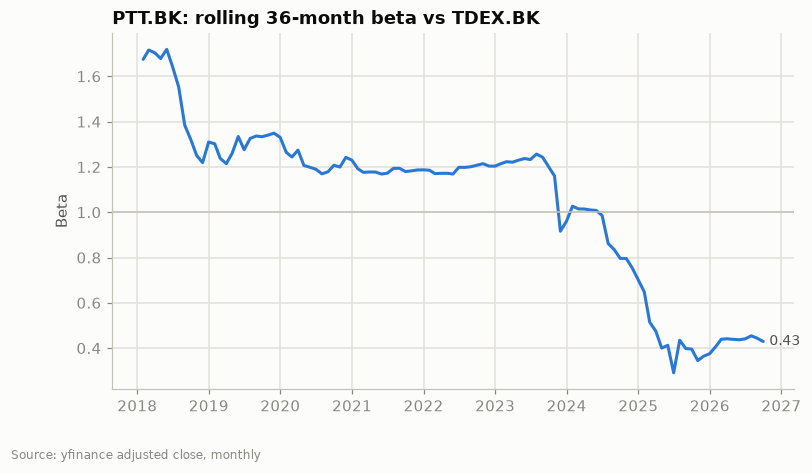

In [31]:
rb = capm.rolling_beta(monthly[STOCK] - RF_3M / 12, monthly[MARKET] - RF_3M / 12, window=36).dropna()
fig, ax = plt.subplots()
ax.plot(rb.index, rb, color=SERIES[0])
ax.axhline(1, color=AXIS, lw=1)
ax.annotate(f"{rb.iloc[-1]:.2f}", (rb.index[-1], rb.iloc[-1]), xytext=(4, 0), textcoords="offset points", va="center",
            fontsize=9, color=INK_2)
ax.set(title=f"{STOCK}: rolling 36-month beta vs {MARKET}", ylabel="Beta")
source_note(fig, "yfinance adjusted close, monthly")
plt.show()

### 5.7 Equity risk premium and $k_e$ for each stock

There are two ways to estimate the market risk premium (docs/05 §5.6):
- **(a) Historical:** the mean of $R_m - r_f$ over the full sample.
- **(b) Implied:** from Gordon on the index, $D_1/P + g - r_f$.

The model uses (a). Then $k_e = r_{f,10Y} + \beta \cdot MRP$.

In [32]:
mrp_hist = capm.historical_mrp(monthly[MARKET], rf=RF_3M / 12, periods_per_year=12)
index_dy = data.trailing_dps(market.dividends[MARKET], ASOF) / market.close.loc[ASOF, MARKET]
mrp_implied = capm.implied_mrp(d1=index_dy * (1 + INDEX_GROWTH), price=1.0, g=INDEX_GROWTH, rf=RF_10Y)
MRP = mrp_hist
print(f"MRP (a) historical {monthly.index.min():%Y}–{monthly.index.max():%Y}: {mrp_hist:.2%} | "
      f"(b) implied: yield {index_dy:.2%} × (1+g) + g {INDEX_GROWTH:.1%} − r_f {RF_10Y:.2%} = {mrp_implied:.2%} | using {MRP:.2%}")

ke_table = betas[["beta", "blume_beta"]].copy()
ke_table["ke"] = capm.capm_required_return(RF_10Y, ke_table["beta"], mrp=MRP)
ke_table["ke_blume"] = capm.capm_required_return(RF_10Y, ke_table["blume_beta"], mrp=MRP)
data.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
ke_table.to_csv(data.PROCESSED_DIR / "capm_ke.csv")
ke_table.style.format({"beta": "{:.2f}", "blume_beta": "{:.2f}", "ke": "{:.2%}", "ke_blume": "{:.2%}"})

MRP (a) historical 2015–2026: 4.14% | (b) implied: yield 2.90% × (1+g) + g 3.0% − r_f 1.70% = 4.29% | using 4.14%


,beta,blume_beta,ke,ke_blume
PTT.BK,0.55,0.70,3.98%,4.60%
PTTEP.BK,0.44,0.62,3.51%,4.29%
ADVANC.BK,0.62,0.75,4.28%,4.80%
AOT.BK,1.23,1.15,6.79%,6.48%
CPALL.BK,0.96,0.98,5.69%,5.74%
KBANK.BK,0.56,0.71,4.03%,4.64%
BBL.BK,0.58,0.72,4.08%,4.67%
SCC.BK,0.88,0.92,5.36%,5.52%
BDMS.BK,0.54,0.69,3.93%,4.57%


---
## 6 · Rational expectations and efficient markets — [docs/06](docs/06_efficient_markets.md)

With rational expectations, the optimal forecast of a return equals its equilibrium return, $R^{of} = R^*$. Under CAPM that means the expected **alpha is zero**. Arbitrage by a few "smart money" traders is enough to remove unexploited profit opportunities.

| Form | Prices reflect | Test below |
|---|---|---|
| Weak | all past prices and volume | autocorrelation, Ljung–Box, runs, variance ratio; MA trading rule |
| Semi-strong | all public information | event study |
| Strong | public and private information | discussion only |

### 6.1 Adaptive vs rational expectations (mean-reverting series, φ = 0.7)

,mean_error,rmse,error_rho_1
adaptive,-0.0117%,1.139%,+0.50
rational,-0.0423%,0.931%,+0.09


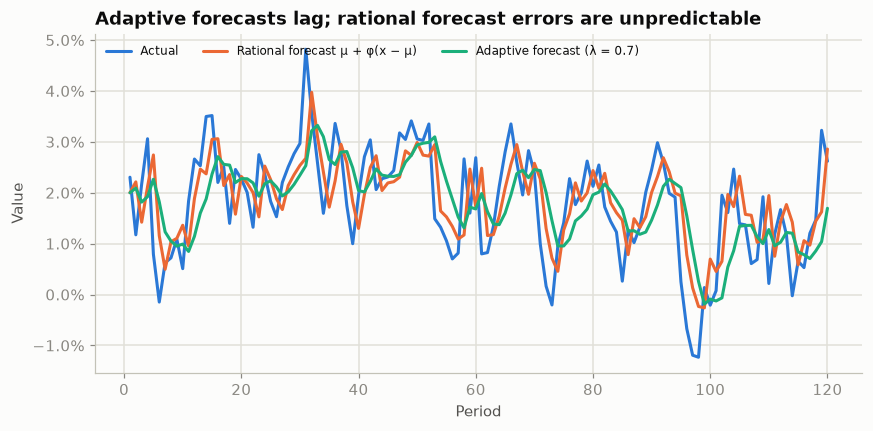

In [33]:
demo = emh.expectations_demo(t=300, phi=0.7, lam=0.7, seed=42)
display(emh.forecast_error_stats(demo).style.format({"mean_error": "{:+.4%}", "rmse": "{:.3%}", "error_rho_1": "{:+.2f}"}))

fig, ax = plt.subplots(figsize=(9, 4))
part = demo.iloc[:120]
ax.plot(part.index, part["actual"], color=SERIES[0], label="Actual")
ax.plot(part.index, part["rational"], color=SERIES[1], label="Rational forecast μ + φ(x − μ)")
ax.plot(part.index, part["adaptive"], color=SERIES[2], label="Adaptive forecast (λ = 0.7)")
ax.yaxis.set_major_formatter(PCT)
ax.set(title="Adaptive forecasts lag; rational forecast errors are unpredictable", xlabel="Period", ylabel="Value")
ax.legend(fontsize=8, ncol=3, loc="upper left")
plt.show()

### 6.2 The test battery on synthetic data (what each result should look like)

In [34]:
synthetic = pd.DataFrame({"iid N(0, 1%²)": emh.simulate_returns("iid", seed=42),
                          "AR(1) φ = 0.3": emh.simulate_returns("ar1", phi=0.3, seed=42)})
emh.weak_form_battery(synthetic, lags=10, q=5).style.format(precision=3).format({"T": "{:.0f}"})

,T,rho_1,rho_1_z,LB_Q(10),LB_p,runs_z,runs_p,VR(5),VR_z,VR_p,reject_5%
"iid N(0, 1%²)",5000,0.027176,1.921621,14.587510,0.147840,-1.102651,0.270179,1.031677,1.022365,0.306608,False
AR(1) φ = 0.3,5000,0.320700,22.676901,563.296535,0.000000,-15.067329,0.000000,1.643676,20.774549,0.000000,True


### 6.3 Weak-form tests on SET data (log returns)

In [35]:
daily_log = returns.log_returns(market.adj_close)
weekly_log = returns.period_returns(market.adj_close, "W-FRI", log=True)
battery = pd.concat({"daily": emh.weak_form_battery(daily_log), "weekly": emh.weak_form_battery(weekly_log)})
battery.style.format(precision=3).format({"T": "{:.0f}"})

**Reading the battery**
- Daily returns reject the iid random walk for most series. For most stocks the pattern is mild mean reversion: a slightly negative first-order autocorrelation, more sign reversals than chance (positive runs z), and VR(5) below 1.
- Two things produce this pattern without implying a profit opportunity: bid–ask bounce, and volatility clustering. Volatility clustering matters because the Ljung–Box and runs tests assume iid returns.
- At the weekly frequency most rejections disappear.
- The EMH needs no *exploitable* predictability after costs. The trading rule below tests exactly that.

### 6.4 Trading rule: 20/100-day moving-average crossover on the market proxy

,CAGR,vol,return/vol,max_drawdown,trades
buy & hold,5.02%,15.1%,0.33,-36.5%,0
MA rule (no cost),3.69%,9.9%,0.37,-26.7%,29
MA rule (after cost),3.41%,9.9%,0.35,-28.4%,29


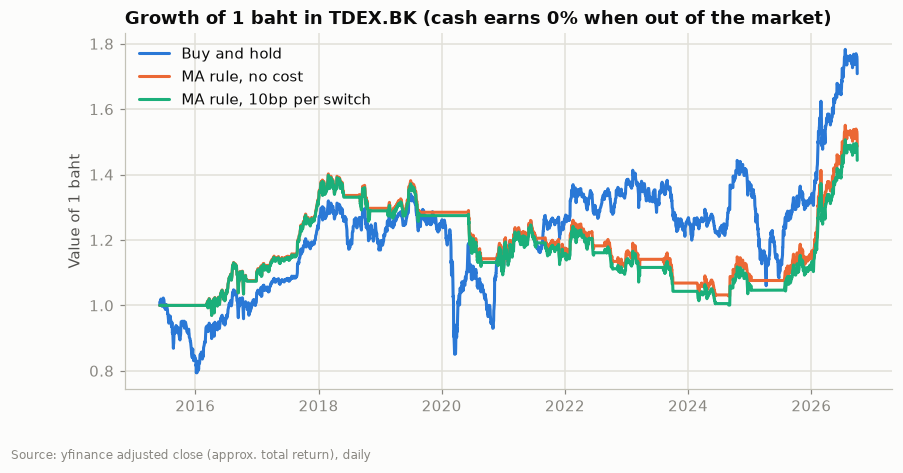

In [36]:
bt = emh.ma_crossover_backtest(market.adj_close[MARKET], short=20, long=100, cost_bp=10)
display(emh.performance_summary(bt).style.format({"CAGR": "{:.2%}", "vol": "{:.1%}", "return/vol": "{:.2f}",
                                                  "max_drawdown": "{:.1%}", "trades": "{:.0f}"}))
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(bt.index, bt["eq_bh"], color=SERIES[0], label="Buy and hold")
ax.plot(bt.index, bt["eq_gross"], color=SERIES[1], label="MA rule, no cost")
ax.plot(bt.index, bt["eq_net"], color=SERIES[2], label="MA rule, 10bp per switch")
ax.set(title=f"Growth of 1 baht in {MARKET} (cash earns 0% when out of the market)", ylabel="Value of 1 baht")
ax.legend()
source_note(fig, "yfinance adjusted close (approx. total return), daily")
plt.show()

The rule cuts volatility and drawdowns because it is out of the market part of the time. It does **not** beat buy-and-hold on return, and costs widen the gap. This matches the weak form: past prices do not offer a reliable excess return.

### 6.5 Semi-strong form: event studies

The first panel checks the method on synthetic data with a +5% abnormal return injected on day 0. The second applies it to real **ex-dividend dates** for the SET stocks. yfinance gives ex-dates, not announcement dates. Adjusted returns add the dividend back, so the mechanical price drop is removed.

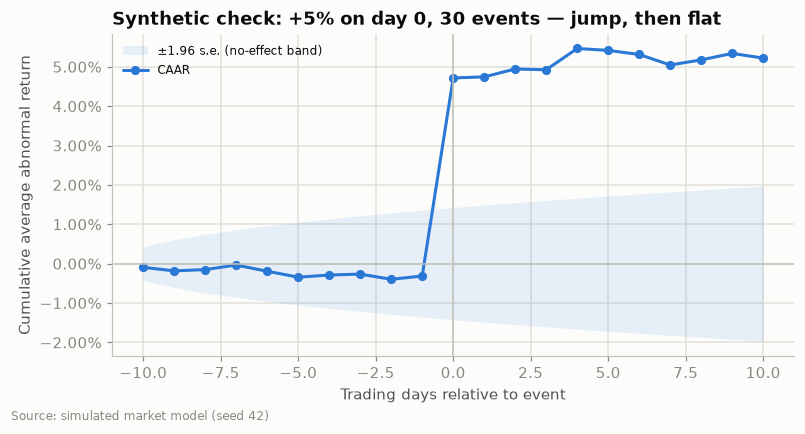

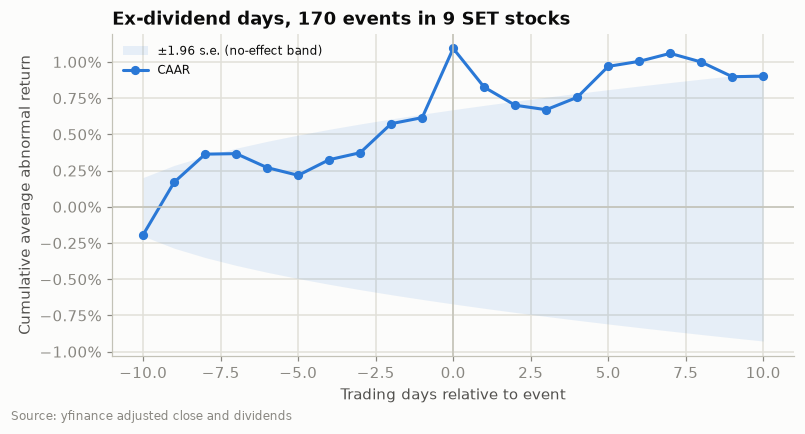

day,-10,-5,-1,0,1,5,10
CAAR,-0.0019,0.0022,0.0062,0.0109,0.0083,0.0097,0.0090
t,-1.8623,0.8606,1.8873,3.1957,2.3110,2.3491,1.9074


In [37]:
asset_syn, market_syn, events_syn = emh.simulate_event_data(jump=0.05, seed=42)
es_syn = emh.event_study(asset_syn, market_syn, events_syn)

daily = returns.simple_returns(market.adj_close)
div_events = data.ex_dividend_events(market.dividends[STOCKS])
es_real = emh.event_study(daily[STOCKS], daily[MARKET], div_events, est=(-250, -30), win=(-10, 10))

for res, title, src in [
    (es_syn, f"Synthetic check: +5% on day 0, {es_syn['n_events']} events — jump, then flat", "simulated market model (seed 42)"),
    (es_real, f"Ex-dividend days, {es_real['n_events']} events in {len(STOCKS)} SET stocks", "yfinance adjusted close and dividends"),
]:
    caar = res["caar"]
    band = 1.96 * res["sigma_ar"] * np.sqrt(np.arange(1, len(caar) + 1)) / np.sqrt(res["n_events"])
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.fill_between(caar.index, -band, band, color=SERIES[0], alpha=0.10, lw=0, label="±1.96 s.e. (no-effect band)")
    ax.plot(caar.index, caar, marker="o", ms=5, color=SERIES[0], label="CAAR")
    ax.axvline(0, color=AXIS, lw=1); ax.axhline(0, color=AXIS, lw=1)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=2))
    ax.set(title=title, xlabel="Trading days relative to event", ylabel="Cumulative average abnormal return")
    ax.legend(fontsize=8, loc="upper left")
    source_note(fig, src)
    plt.show()

pd.DataFrame({"CAAR": es_real["caar"], "t": es_real["t_caar"]}).loc[[-10, -5, -1, 0, 1, 5, 10]].T.style.format(precision=4)

**Interpretation (slide 19)**
- **Synthetic panel.** It shows what efficiency predicts: the price jumps on day 0, with no drift afterwards.
- **Real ex-dividend panel.**
  - The CAAR drifts up in the days before the ex-date and rises again on day 0, where it is clearly significant (see the table). The textbook explanation for the day-0 effect is taxes: the price drops by less than the dividend because Thai individuals pay a 10% withholding tax on dividends. The pre-event drift is consistent with buying to capture the dividend.
  - Over the whole window the CAAR sits close to the edge of the no-effect band, and the effect is about the size of a round-trip trading cost, so it is not a reliable profit opportunity.
  - Using ex-dates instead of announcement dates, and events that overlap across stocks, both blur the picture.
- **Link to CAPM.** Together with the near-zero, mostly insignificant CAPM alphas in §5.3, this supports the practical advice on slide 19: hold a diversified index fund or ETF.

---
## 7 · Integrated valuation — one Thai corporate bond and one SET stock

```
gov curve + ThaiBMA spread ──► y_corp ──► bond price, duration      (§1, §3)
prices ──► returns ──► β ──► k_e = r_f + β·MRP ──► Gordon / two-stage ──► vs market price   (§5, §4)
```

### 7.1 Bond: 5-year, 3% semiannual coupon, A-rated (hypothetical issue)

In [38]:
BOND = dict(par=1_000, coupon_rate=0.03, months=60, freq=2)
BOND_RATING = "A"
BOND_MARKET_PRICE = None    # put a ThaiBMA clean price per 1,000 here to compare model vs market

t_bond = BOND["months"] / 12
y_gov_bond = spreads.gov_yield(GOV_CURVE, t_bond)
spread_bond = spreads.spread_for(BOND_RATING, t_bond, spread_bp)
y_corp = spreads.corporate_yield(GOV_CURVE, BOND_RATING, t_bond, spread_bp)
bond_value = bonds.bond_price(**BOND, ytm=y_corp)
bond_value_after_tax = bonds.bond_price(**BOND, ytm=y_corp, tax_rate=TAX_RATE)
bond_risk = bonds.duration(**BOND, ytm=y_corp)
gov_equivalent = bonds.bond_price(**BOND, ytm=y_gov_bond)

if BOND_MARKET_PRICE is not None:
    market_ytm = bonds.bond_ytm(BOND_MARKET_PRICE, **BOND)
    print(f"Market price {BOND_MARKET_PRICE:,.2f} → YTM {market_ytm:.3%}, implied spread {(market_ytm - y_gov_bond) * 1e4:.0f}bp "
          f"vs ThaiBMA average {spread_bond * 1e4:.0f}bp")
print(f"y_gov(5y) {y_gov_bond:.3%} + spread {spread_bond * 1e4:.0f}bp = {y_corp:.3%} → price {bond_value:,.2f} "
      f"(after 15% coupon tax {bond_value_after_tax:,.2f}); credit costs {gov_equivalent - bond_value:,.2f} vs a government bond")

y_gov(5y) 1.450% + spread 82bp = 2.272% → price 1,034.21 (after 15% coupon tax 1,013.05); credit costs 40.29 vs a government bond


### 7.2 Stock: PTT — CAPM $k_e$, then dividend discount models

PTT.BK: close 40.75 on 2026-09-30; trailing 12-month DPS 2.30 (yield 5.64%)
k_e = 1.70% + 0.55 × 4.14% = 3.98%
Implied g at market price: -1.58% | historical DPS growth 2015–2025: +7.18%
Gordon (g = 1%): 78.01 | two-stage (7.2% for 5y, then 1%): 103.38 | market-implied k_e at g = 1%: 6.70%


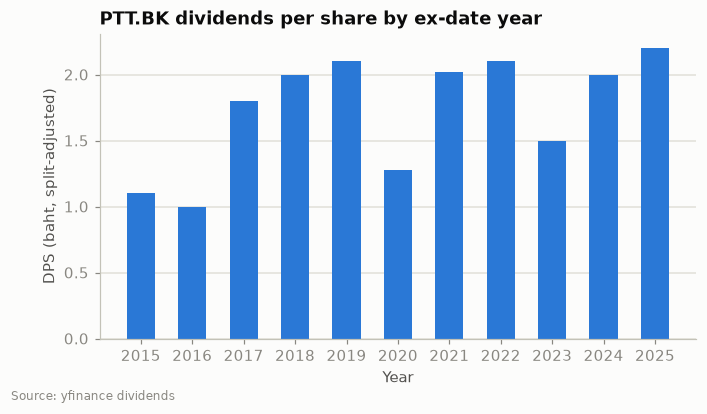

In [39]:
G_LONG = 0.01          # long-run dividend growth after the explicit stage. ASSUMPTION
SHORT_YEARS = 5        # years of the explicit stage in the two-stage model

p_mkt = market.close.loc[ASOF, STOCK]
d0 = data.trailing_dps(market.dividends[STOCK], ASOF)
beta_stock, ke_stock = ke_table.loc[STOCK, "beta"], ke_table.loc[STOCK, "ke"]

dps = data.annual_dps(market.dividends[STOCK]).loc[: ASOF.year - 1]            # complete years only
g_hist = tvm.annualize(dps.iloc[-1] / dps.iloc[0] - 1, 1 / (len(dps) - 1))       # DPS growth (CAGR)
g_implied = equity.gordon_implied_growth_from_d0(p_mkt, d0, ke_stock)           # what the price implies
ke_implied = equity.gordon_implied_return(p_mkt, d0 * (1 + G_LONG), G_LONG)     # market ke if g = G_LONG

gordon_value = equity.gordon_price(ke_stock, G_LONG, d0=d0)
g_short = g_hist                                                                 # first stage: historical DPS growth
two_stage_value = equity.two_stage_ddm(d0, g_short, SHORT_YEARS, G_LONG, ke_stock)

print(f"{STOCK}: close {p_mkt:.2f} on {ASOF:%Y-%m-%d}; trailing 12-month DPS {d0:.2f} (yield {d0 / p_mkt:.2%})")
print(f"k_e = {RF_10Y:.2%} + {beta_stock:.2f} × {MRP:.2%} = {ke_stock:.2%}")
print(f"Implied g at market price: {g_implied:+.2%} | historical DPS growth {dps.index[0]}–{dps.index[-1]}: {g_hist:+.2%}")
print(f"Gordon (g = {G_LONG:.0%}): {gordon_value:.2f} | two-stage ({g_short:.1%} for {SHORT_YEARS}y, then {G_LONG:.0%}): "
      f"{two_stage_value:.2f} | market-implied k_e at g = {G_LONG:.0%}: {ke_implied:.2%}")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(dps.index.astype(str), dps, width=0.55, color=SERIES[0])
ax.grid(axis="x", visible=False)
ax.set(title=f"{STOCK} dividends per share by ex-date year", xlabel="Year", ylabel="DPS (baht, split-adjusted)")
source_note(fig, "yfinance dividends")
plt.show()

In [40]:
ke_axis = sorted({round(ke_stock, 4), round(ke_table.loc[STOCK, "ke_blume"], 4), 0.06, 0.08, 0.10})
g_axis = [-0.02, -0.01, 0.0, 0.01, 0.02]
value_grid = pd.DataFrame([[equity.gordon_price(k, g, d0=d0) if k > g else np.nan for g in g_axis] for k in ke_axis],
                          index=pd.Index([f"{k:.2%}" for k in ke_axis], name="k_e"),
                          columns=pd.Index([f"{g:+.0%}" for g in g_axis], name="g"))
print(f"Gordon value of {STOCK} (D0 = {d0:.2f}) — market price {p_mkt:.2f}")
value_grid.style.format("{:.1f}").background_gradient(cmap=SEQ, axis=None)

Gordon value of PTT.BK (D0 = 2.30) — market price 40.75


g,-2%,-1%,+0%,+1%,+2%
k_e,,,,,
3.98%,37.7,45.7,57.8,78.0,118.5
4.60%,34.2,40.7,50.0,64.5,90.2
6.00%,28.2,32.5,38.3,46.5,58.6
8.00%,22.5,25.3,28.7,33.2,39.1
10.00%,18.8,20.7,23.0,25.8,29.3


**Reading the stock result**
- The CAPM $k_e$ is low for two reasons: PTT's beta against the SET50 ETF is well below 1, and the placeholder risk-free rate is low. At that $k_e$, the Gordon model puts PTT well above its market price.
- The market price says something different. At the CAPM $k_e$ it implies dividends *shrinking* forever (the implied $g$ above). Equivalently, if dividends grow at `G_LONG`, the market is pricing in a much higher required return (the market-implied $k_e$ in the summary).
- This is the point of slides 16–17. The model price is extremely sensitive to $k_e - g$ (see the grid). Investors with different risk assessments, or different oil-price views, will disagree.
- Before acting, check the inputs: $r_f$ from the actual ThaiBMA curve, the MRP choice, the Blume-adjusted beta, and whether trailing DPS is a fair $D_0$ for a commodity-linked payer.

### 7.3 One-page summary

In [41]:
summary = pd.DataFrame([
    ("Bond", "Instrument", f"{BOND['months'] // 12}y {BOND['coupon_rate']:.0%} coupon, {BOND['freq']}×/yr, par {BOND['par']:,}, {BOND_RATING}"),
    ("Bond", "Government yield (placeholder curve)", f"{y_gov_bond:.3%}"),
    ("Bond", "ThaiBMA spread (ttm 3–5Y)", f"{spread_bond * 1e4:.0f} bp"),
    ("Bond", "Discount yield", f"{y_corp:.3%}"),
    ("Bond", "Model price (pre-tax / after 15% coupon tax)", f"{bond_value:,.2f} / {bond_value_after_tax:,.2f}"),
    ("Bond", "Macaulay / modified duration", f"{bond_risk['macaulay']:.2f} / {bond_risk['modified']:.2f}"),
    ("Bond", "Convexity / DV01 per 1,000", f"{bond_risk['convexity']:.1f} / {bond_risk['dv01']:.3f}"),
    ("Bond", "Market comparison", "set BOND_MARKET_PRICE" if BOND_MARKET_PRICE is None else f"market {BOND_MARKET_PRICE:,.2f} vs model {bond_value:,.2f}"),
    ("Stock", "Ticker / market price", f"{STOCK} / {p_mkt:.2f} ({ASOF:%Y-%m-%d})"),
    ("Stock", "Beta vs " + MARKET + f" ({BETA_MONTHS}m)", f"{beta_stock:.2f} (Blume {ke_table.loc[STOCK, 'blume_beta']:.2f})"),
    ("Stock", "r_f (10Y) / MRP", f"{RF_10Y:.2%} / {MRP:.2%}"),
    ("Stock", "Cost of equity k_e (CAPM)", f"{ke_stock:.2%}"),
    ("Stock", "D0 (trailing 12m) / dividend yield", f"{d0:.2f} / {d0 / p_mkt:.2%}"),
    ("Stock", "Implied g at market price", f"{g_implied:+.2%} (historical DPS CAGR {g_hist:+.2%})"),
    ("Stock", f"Gordon value (g = {G_LONG:.0%}) / two-stage value", f"{gordon_value:.2f} / {two_stage_value:.2f}"),
    ("Stock", "Model ÷ market (Gordon)", f"{gordon_value / p_mkt:.2f}×"),
    ("Stock", f"Market-implied k_e at g = {G_LONG:.0%}", f"{ke_implied:.2%}"),
], columns=["asset", "item", "value"]).set_index(["asset", "item"])
summary

value
asset item                                                                             
Bond  Instrument                                      5y 3% coupon, 2×/yr, par 1,000, A
      Government yield (placeholder curve)                                       1.450%
      ThaiBMA spread (ttm 3–5Y)                                                   82 bp
      Discount yield                                                             2.272%
      Model price (pre-tax / after 15% coupon tax)                  1,034.21 / 1,013.05
      Macaulay / modified duration                                          4.69 / 4.63
      Convexity / DV01 per 1,000                                           24.6 / 0.479
      Market comparison                                           set BOND_MARKET_PRICE
Stock Ticker / market price                                 PTT.BK / 40.75 (2026-09-30)
      Beta vs TDEX.BK (60m)                                           0.55 (Blume 0.70)
      r_f (10Y) / MRP                                                     1.70% / 4.14%
      Cost of equity k_e (CAPM)                                                   3.98%
      D0 (trailing 12m) / dividend yield                                   2.30 / 5.64%
      Implied g at market price                     -1.58% (historical DPS CAGR +7.18%)
      Gordon value (g = 1%) / two-stage value                            78.01 / 103.38
      Model ÷ market (Gordon)                                                     1.91×
      Market-implied k_e at g = 1%                                                6.70%

---
## Limitations and next steps
- **Placeholders.** `GOV_CURVE`, `EXPECTED_INFLATION`, `INDEX_GROWTH` and `G_LONG` are assumptions. Load the ThaiBMA government curve and BOT data (`data/raw/bot_rates.csv`) to replace them.
- **Market proxy.** `TDEX.BK` (a SET50 ETF) stands in for the SET TRI. yfinance adjusted close is only an approximate total return.
- **Events.** The event study uses ex-dividend dates, not announcement dates. BOT MPC rate surprises would need BOT data.
- **Refresh.** To re-download prices, run `data.load_market_data(refresh=True)`. The cache lives in `data/raw/set_daily_*.parquet`.
- **Splitting.** The seven sections map one-to-one to the `notebooks/0X_*.ipynb` files in docs/07 §7.1 if you want to split them later.

## ✓ Assertions

These re-check the key values from docs/07 §7.5. The full set runs with `pytest` in `tests/`.

In [42]:
checks = {
    "fv(100, 10%, 2) = 121.00": abs(tvm.fv(100, 0.10, 2) - 121.00) < 0.01,
    "pv(5m, 6% monthly, 10y) = 2,748,163.67": abs(tvm.pv(5e6, 0.06, 10, m=12) - 2_748_163.67) < 0.01,
    "annuity due lottery = 9,364,920.09": abs(tvm.annuity_pv(1e6, 0.10, 20, due=True) - 9_364_920.09) < 0.01,
    "mortgage payment = 4,417.63": abs(tvm.annuity_payment(800_000, 0.0525 / 12, 360) - 4_417.63) < 0.01,
    "forward f(1,1) = 4.0098%": abs(tvm.forward_rate(0.02, 1, 0.03, 2) - 0.040098) < 1e-6,
    "bond 10%, 8y, y 12.25% = 889.20": abs(bonds.bond_price(1000, 0.10, 96, 0.1225) - 889.20) < 0.01,
    "Table 1 YTMs": np.allclose(bonds.table1()["ytm"], [0.0713, 0.0848, 0.1000, 0.1175, 0.1381], atol=1e-4),
    "Table 2 next-year prices": bonds.table2()["next_price"].round().tolist() == [503, 516, 597, 741, 917, 1000],
    "CFA India semiannual = 89.88": abs(bonds.bond_price(100, 0.067, 240, 0.077, freq=2) - 89.88) < 0.01,
    "duration 6.7590 / 6.1446 / 52.79": np.allclose([risk["macaulay"], risk["modified"], risk["convexity"]],
                                                    [6.7590, 6.1446, 52.79], atol=[1e-4, 1e-4, 0.01]),
    "pv.ipynb snapshot 944,603.44 / 932,139.21": abs(price - 944_603.44) < 0.01 and abs(price_after_tax - 932_139.21) < 0.01,
    "Gordon 16.67 / 22.22 / 28.57": [round(equity.gordon_price(k, 0.03, d1=2), 2) for k in (0.15, 0.12, 0.10)] == [16.67, 22.22, 28.57],
    "two-stage 11.66 / 13.05 / 14.94 / 17.67": [round(equity.two_stage_ddm(1.5, 0.06, 3, g, 0.15), 2)
                                                for g in (0, 0.02, 0.04, 0.06)] == [11.66, 13.05, 14.94, 17.67],
    "CAPM 2.5% + 1.2 × 5.5% = 9.10%": abs(capm.capm_required_return(0.025, 1.2, rm=0.08) - 0.091) < 1e-4,
    "geometric mean [10%, −10%] = −0.501%": abs(returns.geometric_mean([0.10, -0.10]) + 0.00501) < 1e-5,
    "synthetic event study: +5% jump on day 0": abs(es_syn["caar"][0] - es_syn["caar"][-1] - 0.05) < 0.01,
    "rate build-up adds up to the corporate yield": abs(build_up["total"] - spreads.corporate_yield(GOV_CURVE, "A", 5, spread_bp)) < 1e-12,
    "SML distance = 12 × regression alpha": bool(np.allclose(sml_alpha, betas["alpha"] * 12)),
    "§7 stock: k_e > long-run g": ke_stock > G_LONG,
}
result = pd.Series(checks, name="pass")
display(result.to_frame())
assert result.all(), result[~result]
print(f"All {len(result)} checks passed.")

,pass
"fv(100, 10%, 2) = 121.00",True
"pv(5m, 6% monthly, 10y) = 2,748,163.67",True
"annuity due lottery = 9,364,920.09",True
"mortgage payment = 4,417.63",True
"forward f(1,1) = 4.0098%",True
"bond 10%, 8y, y 12.25% = 889.20",True
Table 1 YTMs,True
Table 2 next-year prices,True
CFA India semiannual = 89.88,True
duration 6.7590 / 6.1446 / 52.79,True


All 19 checks passed.
